# Civet Behavior Classification — ResNet18 Training

## Step 1: Setup

1.1 Mount Google Drive

In [ ]:
# ===== Cell 1.1: Mount Google Drive (run once per session) =====
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


1.2 Imports and configuration

In [ ]:
# ===== Cell 1.2: Imports and configuration (run once per session) =====
import re, random, shutil
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from collections import Counter

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# ---------- Paths ----------
BASE    = Path('/content/drive/MyDrive/civet2')
SRC     = BASE / 'sorted'     # training images (the only source used for training)
MODELS  = BASE / 'models'     # saved models
RESULTS = BASE / 'results'    # figures, tables, reports
MODELS.mkdir(parents=True, exist_ok=True)
RESULTS.mkdir(parents=True, exist_ok=True)
assert 'test' not in SRC.parts, 'Test data must never be used for training'

# ---------- Constants ----------
IMG_EXT = {'.jpg', '.jpeg', '.png'}
CAMERAS = ['A01', 'A02', 'A03', 'A04']
NAME_RE = re.compile(r'(A0[1-4])_(\d{14})_t?(\d{5})')   # e.g. A03_20260405140327_t07460 (some files lack "_t")

# Behavior folder (leaf) -> class used for training
MERGE = {
    'Resting': 'Inactive', 'Sitting': 'Inactive', 'Standing': 'Inactive',
    'Feeding': 'Feeding_Drinking', 'Drinking': 'Feeding_Drinking',
    'Locomotion': 'Locomotion',
    'Not_visible': 'Not_visible',
}
# Training class -> ethogram group
GROUP = {'Inactive': 'Inactive', 'Locomotion': 'Active',
         'Feeding_Drinking': 'Active', 'Not_visible': 'Not visible'}

print('Config loaded. MERGE keys:', list(MERGE))

Config loaded. MERGE keys: ['Resting', 'Sitting', 'Standing', 'Feeding', 'Drinking', 'Locomotion', 'Not_visible']


1.3 Helper functions

In [ ]:
# ===== Cell 1.3: Helper functions (run once per session) =====
MERGE_KEYS = {k.lower(): k for k in MERGE}   # case-insensitive lookup

def canonical(folder):
    """Map a folder name to its MERGE key, ignoring case and extra spaces."""
    return MERGE_KEYS.get(folder.strip().lower().replace(' ', '_'))

def parse_name(path):
    """Return (camera, clip_id, seconds_from_clip_start) from a file name, or None."""
    m = NAME_RE.search(Path(path).stem)
    if not m:
        return None
    cam, start, t = m.groups()
    return cam, f'{cam}_{start}', int(t)

def list_images(root):
    """Find all images under root, skipping folders that start with '_' (e.g. _excluded).
    The behavior is the name of the folder that directly contains the image."""
    out = []
    for p in root.rglob('*'):
        if p.suffix.lower() not in IMG_EXT:
            continue
        if any(part.strip().startswith('_') for part in p.relative_to(root).parts):
            continue
        out.append((p, p.parent.name))
    return out

folders = Counter(b for _, b in list_images(SRC))
for f, n in sorted(folders.items()):
    print(f'{f!r:20} {n:5} images -> {canonical(f) or "UNKNOWN"}')

IMG_SIZE = 224

def prep(img_bgr, steps=False):
    """Gray -> Histogram Equalization -> Gaussian 3x3 -> 3 channels -> 224x224 (uint8).
    Must be identical for training, validation and all inference."""
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    he   = cv2.equalizeHist(gray)
    blur = cv2.GaussianBlur(he, (3, 3), 0)
    out  = cv2.resize(cv2.merge([blur, blur, blur]), (IMG_SIZE, IMG_SIZE),
                      interpolation=cv2.INTER_AREA)
    if steps:
        return {'Original': cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB), 'Grayscale': gray,
                'Histogram Eq.': he, 'Gaussian 3x3': blur, 'Final 224x224': out}
    return out

'Drinking'              24 images -> Drinking
'Feeding'              318 images -> Feeding
'Locomotion'           719 images -> Locomotion
'Not_visible'          230 images -> Not_visible
'Resting'              248 images -> Resting
'Sitting'               88 images -> Sitting
'Standing'              73 images -> Standing


## Step 2: Data Inventory
Check file names, count images per class and camera, show sample images.

Valid images: 1700
Unknown folders: {}
Invalid file names: 0


camera                        A01  A02  A03  A04  total  max_one_camera_%
cls              behavior                                                
Feeding_Drinking Drinking       0    0    0   24     24             100.0
                 Feeding        0    0  318    0    318             100.0
Inactive         Resting        0    0  140  108    248              56.0
                 Sitting        7    6   23   52     88              59.0
                 Standing      14   33   26    0     73              45.0
Locomotion       Locomotion   114   37  323  245    719              45.0
Not_visible      Not_visible   55   56   60   59    230              26.0


Images per training class:
cls
Locomotion          719
Inactive            409
Feeding_Drinking    342
Not_visible         230

Classes where >70% of images come from one camera (limitation):
['Feeding_Drinking']


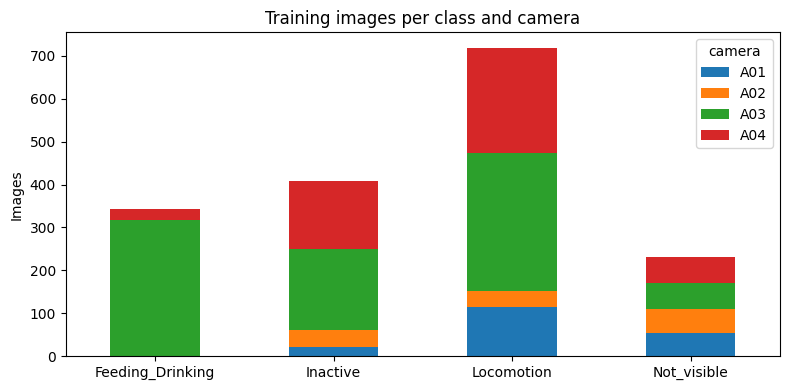

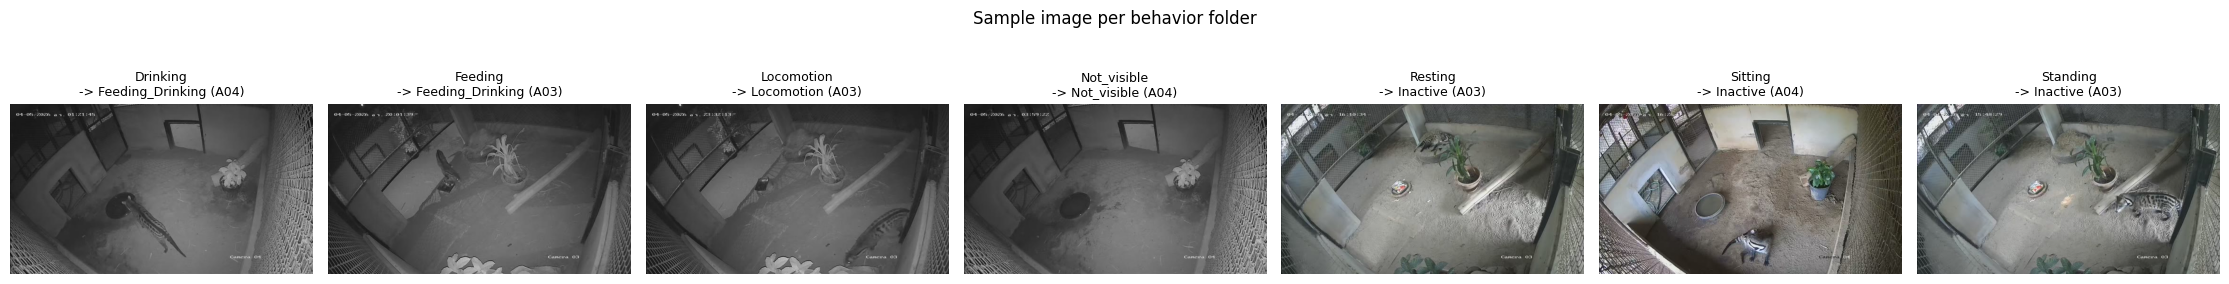


Saved: /content/drive/MyDrive/civet2/results/c2_inventory.csv


In [ ]:
# ===== Cell 2: Inventory, file name check and image counts =====
# Output: results/c2_inventory.csv (used by later cells), c2_counts.png, c2_samples.png

# ---------- Scan images and parse file names ----------
rows, bad_name, bad_folder = [], [], []
for p, folder in list_images(SRC):
    behavior = canonical(folder)
    info = parse_name(p)
    if behavior is None:
        bad_folder.append(folder); continue
    if info is None:
        bad_name.append((behavior, p.name)); continue
    cam, clip, t = info
    rows.append({'path': str(p), 'behavior': behavior, 'cls': MERGE[behavior],
                 'group': GROUP[MERGE[behavior]], 'camera': cam, 'clip': clip, 't': t})

inv = pd.DataFrame(rows)
print(f'Valid images: {len(inv)}')
print(f'Unknown folders: {dict(Counter(bad_folder))}')
print(f'Invalid file names: {len(bad_name)}')
for b, n in bad_name[:10]:
    print('   ', b, n)
assert len(inv) > 0, 'No valid images found'

# ---------- Count table: behavior x camera ----------
count = (inv.pivot_table(index=['cls', 'behavior'], columns='camera',
                         values='path', aggfunc='count', fill_value=0)
            .reindex(columns=CAMERAS, fill_value=0))
count['total'] = count.sum(axis=1)
count['max_one_camera_%'] = (count[CAMERAS].max(axis=1) / count['total'] * 100).round()
display(count)

cls_count = inv['cls'].value_counts()
print('\nImages per training class:')
print(cls_count.to_string())
print('\nClasses where >70% of images come from one camera (limitation):')
cam_share = inv.groupby('cls')['camera'].agg(lambda s: s.value_counts(normalize=True).max())
print([c for c, v in cam_share.items() if v > 0.7])

# ---------- Figure 1: stacked bar chart of images per class and camera ----------
pv = inv.pivot_table(index='cls', columns='camera', values='path',
                     aggfunc='count', fill_value=0).reindex(columns=CAMERAS, fill_value=0)
pv.plot(kind='bar', stacked=True, figsize=(8, 4))
plt.title('Training images per class and camera')
plt.ylabel('Images'); plt.xlabel(''); plt.xticks(rotation=0)
plt.tight_layout(); plt.savefig(RESULTS / 'c2_counts.png', dpi=120); plt.show()

# ---------- Figure 2: one sample image per behavior folder ----------
behaviors = sorted(inv['behavior'].unique())
fig, ax = plt.subplots(1, len(behaviors), figsize=(3.2 * len(behaviors), 3.4))
for a, b in zip(np.atleast_1d(ax), behaviors):
    r = inv[inv['behavior'] == b].sample(1, random_state=SEED).iloc[0]
    a.imshow(cv2.cvtColor(cv2.imread(r['path']), cv2.COLOR_BGR2RGB))
    a.set_title(f"{b}\n-> {r['cls']} ({r['camera']})", fontsize=9)
    a.axis('off')
plt.suptitle('Sample image per behavior folder')
plt.tight_layout(); plt.savefig(RESULTS / 'c2_samples.png', dpi=120); plt.show()

# ---------- Save inventory for later cells ----------
inv.to_csv(RESULTS / 'c2_inventory.csv', index=False)
print('\nSaved:', RESULTS / 'c2_inventory.csv')

## Step 3: Train / Validation Split
Cap each class at 500 images (round-robin across cameras), then split each clip by time:
the last 20% of frames go to validation and 3 frames at the boundary are dropped,
because frames 5 s apart are near-duplicates (a random split would leak).

Images per class after cap:
cls
Inactive            409
Locomotion          500
Feeding_Drinking    342
Not_visible         230

Dropped at boundaries (gap): 72

Train / val per class:


split,train,val,val_%
cls,,,
Inactive,309,82,21.0
Locomotion,380,99,20.7
Feeding_Drinking,267,66,19.8
Not_visible,160,46,22.3


Val images per class and camera:


camera,A01,A02,A03,A04
cls,,,,
Inactive,4,8,38,32
Locomotion,23,7,35,34
Feeding_Drinking,0,0,63,3
Not_visible,11,11,12,12


All classes have >=10% validation. 


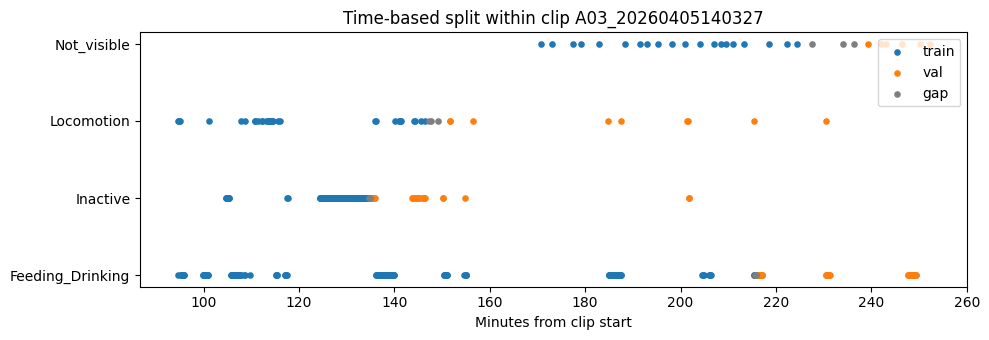

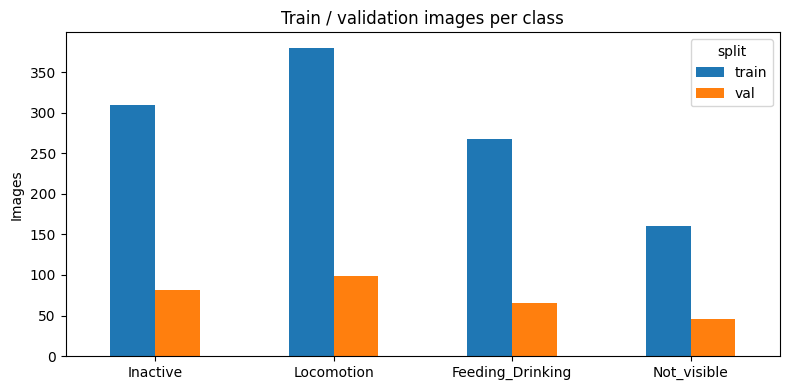

Saved: /content/drive/MyDrive/civet2/results/c3_split.csv (1409 images)


In [ ]:
# ===== Cell 3: Train / validation split (time-based within each clip) =====
# Input : results/c2_inventory.csv
# Output: results/c3_split.csv, c3_time_split.png, c3_split_counts.png

CAP      = 500    # max images per class
VAL_FRAC = 0.2    # last 20% of each clip (per class) -> validation
GAP      = 3      # frames dropped at the train/val boundary
MIN_CLIP = 10     # clips with fewer frames go entirely to train
CLASSES  = ['Inactive', 'Locomotion', 'Feeding_Drinking', 'Not_visible']

inv = pd.read_csv(RESULTS / 'c2_inventory.csv')

# ---------- Cap each class, sampling round-robin across cameras ----------
def cap_round_robin(df, cap):
    if len(df) <= cap:
        return df
    pools = {c: g.sample(frac=1, random_state=SEED).index.tolist()
             for c, g in df.groupby('camera')}
    keep = []
    while len(keep) < cap:
        for c in sorted(pools):
            if pools[c] and len(keep) < cap:
                keep.append(pools[c].pop())
    return df.loc[keep]

capped = pd.concat([cap_round_robin(g, CAP) for _, g in inv.groupby('cls')])
print('Images per class after cap:')
print(capped['cls'].value_counts().reindex(CLASSES).to_string())

# ---------- Time-based split within each clip and class ----------
def split_clip(g):
    g = g.sort_values('t').copy()
    n = len(g)
    if n < MIN_CLIP:
        g['split'] = 'train'
        return g
    cut = int(round(n * (1 - VAL_FRAC)))
    pos = np.arange(n)
    g['split'] = np.where(pos >= cut, 'val',
                 np.where(pos >= cut - GAP, 'gap', 'train'))
    return g

all_rows = pd.concat([split_clip(g) for _, g in capped.groupby(['clip', 'cls'])])
split = all_rows[all_rows['split'] != 'gap'].reset_index(drop=True)
print(f"\nDropped at boundaries (gap): {(all_rows['split'] == 'gap').sum()}")

tab = pd.crosstab(split['cls'], split['split']).reindex(CLASSES, fill_value=0)
tab['val_%'] = (tab['val'] / tab.sum(axis=1) * 100).round(1)
print('\nTrain / val per class:'); display(tab)
print('Val images per class and camera:')
display(pd.crosstab(split.loc[split['split'] == 'val', 'cls'],
                    split.loc[split['split'] == 'val', 'camera']).reindex(CLASSES, fill_value=0))
low = tab.index[tab['val_%'] < 10].tolist()
print('WARNING - classes with <10% validation:' if low else 'All classes have >=10% validation.', low or '')

# ---------- Figure 1: time split of the largest clip ----------
clip_id = all_rows['clip'].value_counts().idxmax()
g = all_rows[all_rows['clip'] == clip_id]
colors = {'train': 'tab:blue', 'val': 'tab:orange', 'gap': 'tab:gray'}
plt.figure(figsize=(10, 3.5))
for s, c in colors.items():
    d = g[g['split'] == s]
    plt.scatter(d['t'] / 60, d['cls'], c=c, s=14, label=s)
plt.title(f'Time-based split within clip {clip_id}')
plt.xlabel('Minutes from clip start'); plt.legend(loc='upper right')
plt.tight_layout(); plt.savefig(RESULTS / 'c3_time_split.png', dpi=120); plt.show()

# ---------- Figure 2: train / val images per class ----------
tab[['train', 'val']].plot(kind='bar', figsize=(8, 4))
plt.title('Train / validation images per class')
plt.ylabel('Images'); plt.xlabel(''); plt.xticks(rotation=0)
plt.tight_layout(); plt.savefig(RESULTS / 'c3_split_counts.png', dpi=120); plt.show()

# ---------- Save ----------
split.to_csv(RESULTS / 'c3_split.csv', index=False)
print('Saved:', RESULTS / 'c3_split.csv', f'({len(split)} images)')

split,original,train,val,gap,removed_by_cap,val_%
cls,,,,,,
Inactive,409,309,82,18,0,21
Locomotion,719,380,99,21,219,21
Feeding_Drinking,342,267,66,9,0,20
Not_visible,230,160,46,24,0,22
TOTAL,1700,1116,293,72,219,21


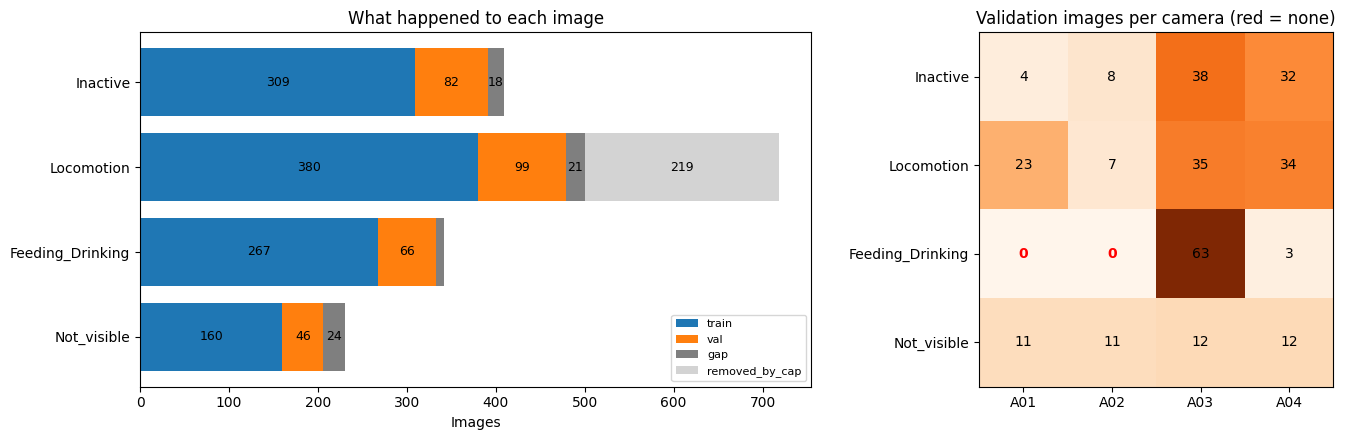

In [ ]:
# ===== Cell 3b: Readable summary of the split =====
# Uses all_rows / inv from Cell 3. Output: results/c3_summary.png

# ---------- One summary table ----------
summary = (pd.crosstab(all_rows['cls'], all_rows['split'])
             .reindex(index=CLASSES, columns=['train', 'val', 'gap'], fill_value=0))
summary.insert(0, 'original', inv['cls'].value_counts().reindex(CLASSES))
summary['removed_by_cap'] = summary['original'] - summary[['train', 'val', 'gap']].sum(axis=1)
summary['val_%'] = (summary['val'] / (summary['train'] + summary['val']) * 100).round().astype(int)
summary.loc['TOTAL'] = summary.sum()
summary.loc['TOTAL', 'val_%'] = round(summary.loc['TOTAL', 'val'] /
                                      (summary.loc['TOTAL', 'train'] + summary.loc['TOTAL', 'val']) * 100)
display(summary)

# ---------- Figure: where every image went + val coverage per camera ----------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={'width_ratios': [3, 2]})

parts = {'train': 'tab:blue', 'val': 'tab:orange', 'gap': 'tab:gray', 'removed_by_cap': 'lightgray'}
left = np.zeros(len(CLASSES))
for col, color in parts.items():
    vals = summary.loc[CLASSES, col].values
    bars = ax1.barh(CLASSES, vals, left=left, color=color, label=col)
    ax1.bar_label(bars, labels=[str(v) if v >= 15 else '' for v in vals], label_type='center', fontsize=9)
    left += vals
ax1.invert_yaxis()
ax1.set_xlabel('Images')
ax1.set_title('What happened to each image')
ax1.legend(loc='lower right', fontsize=8)

val = split[split['split'] == 'val']
heat = pd.crosstab(val['cls'], val['camera']).reindex(index=CLASSES, columns=CAMERAS, fill_value=0)
ax2.imshow(heat.values, cmap='Oranges')
for i in range(len(CLASSES)):
    for j in range(len(CAMERAS)):
        v = heat.values[i, j]
        ax2.text(j, i, v, ha='center', va='center', color='red' if v == 0 else 'black',
                 fontweight='bold' if v == 0 else 'normal')
ax2.set_xticks(range(len(CAMERAS)), CAMERAS)
ax2.set_yticks(range(len(CLASSES)), CLASSES)
ax2.set_title('Validation images per camera (red = none)')

plt.tight_layout(); plt.savefig(RESULTS / 'c3_summary.png', dpi=120); plt.show()

## Step 4: Preprocessing
Grayscale → Histogram Equalization → Gaussian blur 3×3 → stack to 3 channels → resize 224×224.
The same `prep()` is used for training, validation and all test videos.

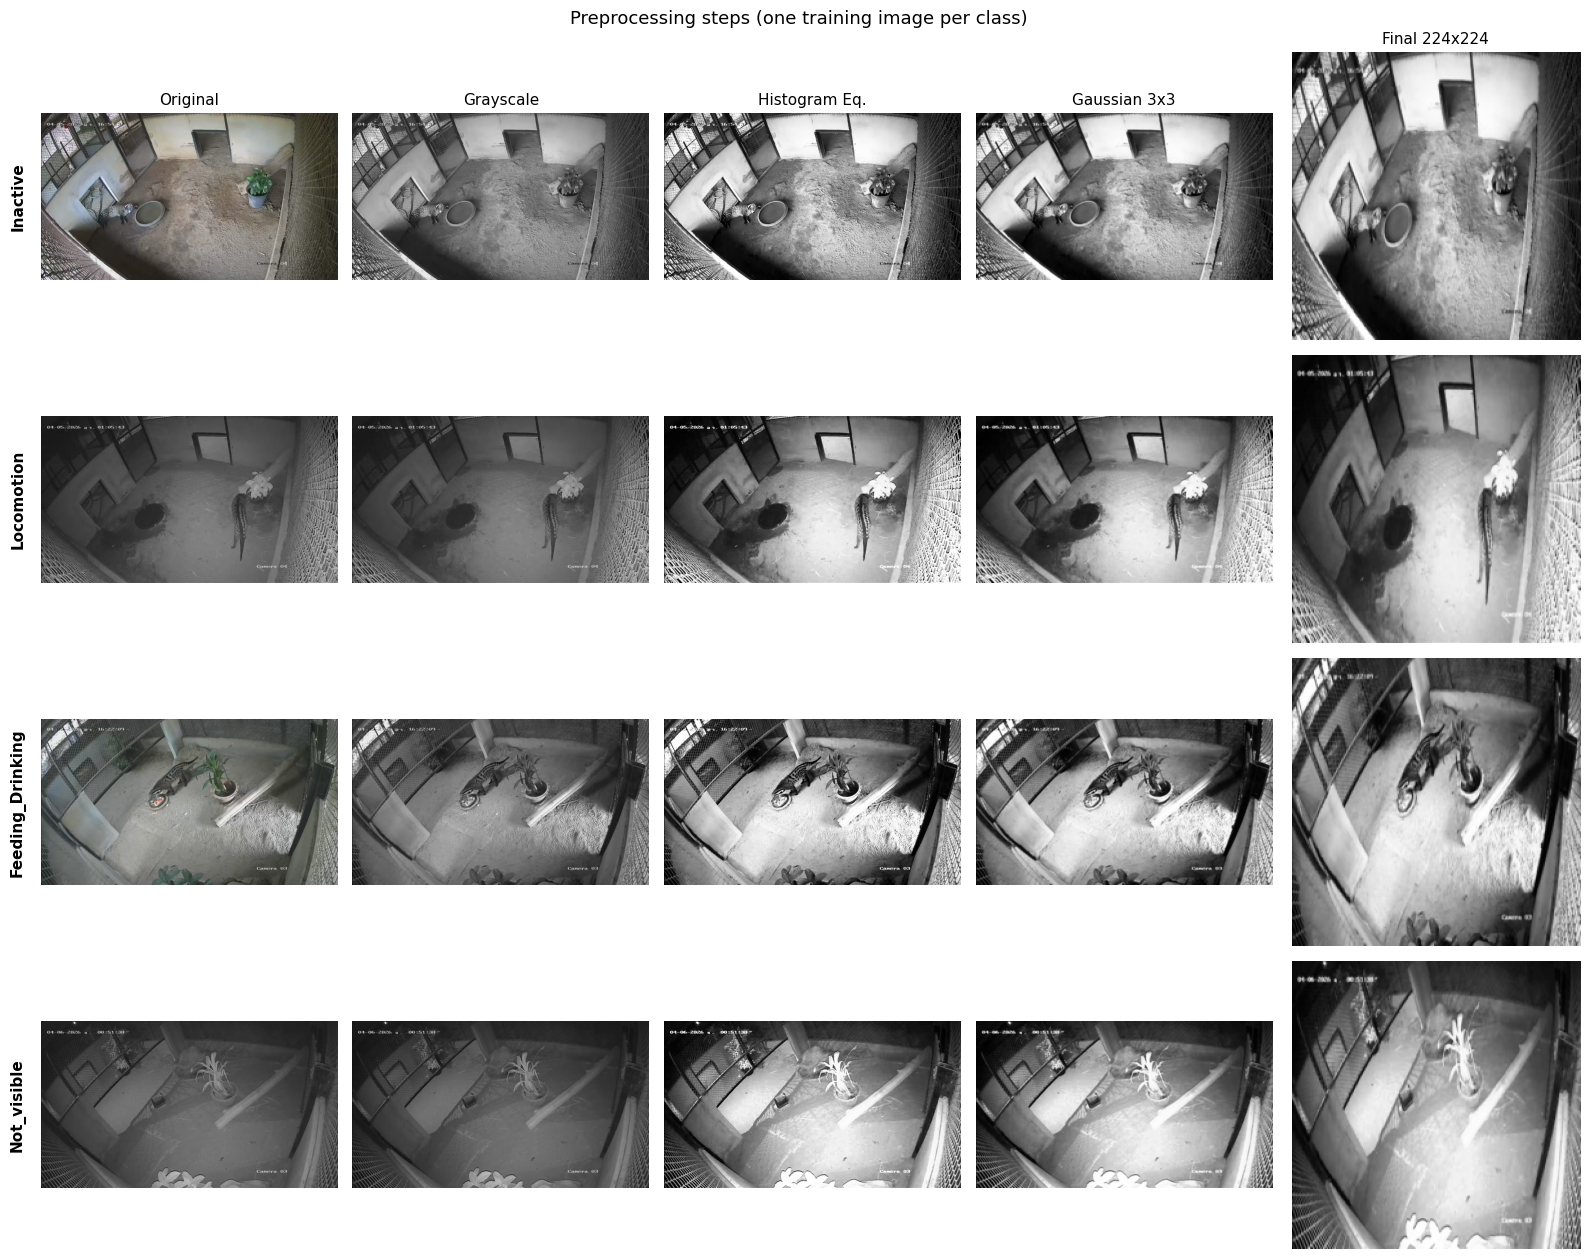

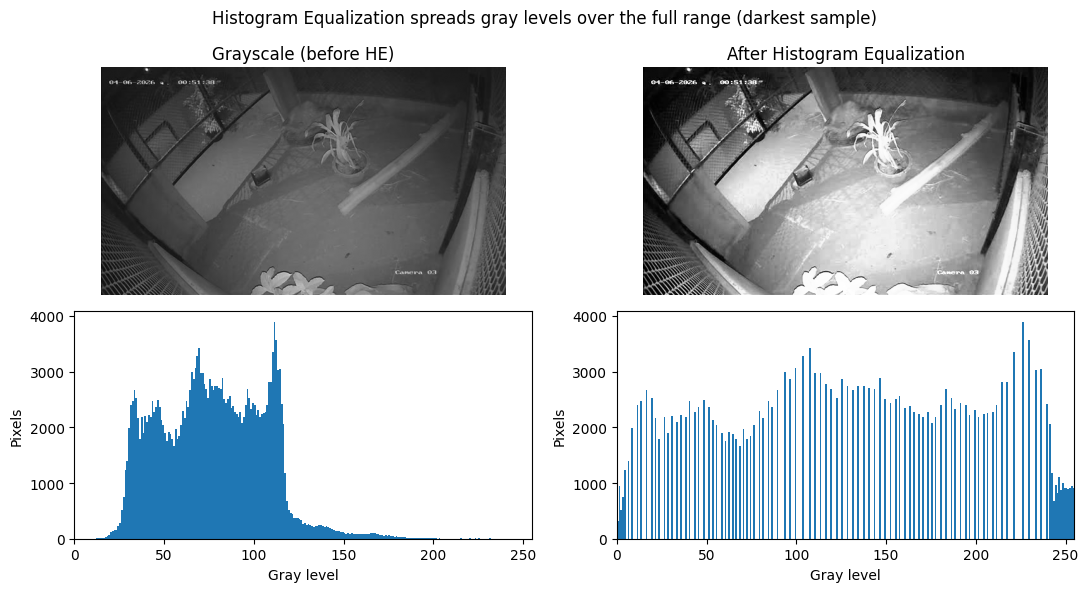

Final image shape: (224, 224, 3)


In [ ]:
# ===== Cell 4: Preprocessing figures =====
# Input : results/c3_split.csv | Output: c4_preprocessing.png, c4_histogram.png
# Note  : images are resized to 224x224 to match ImageNet pretraining;
#         the aspect-ratio distortion is identical for training and testing.

split = pd.read_csv(RESULTS / 'c3_split.csv')
CLASSES = ['Inactive', 'Locomotion', 'Feeding_Drinking', 'Not_visible']
samples = {c: split[(split['cls'] == c) & (split['split'] == 'train')]
                .sample(1, random_state=SEED).iloc[0]['path'] for c in CLASSES}

# ---------- Figure 1: each preprocessing step, one image per class ----------
fig, ax = plt.subplots(len(CLASSES), 5, figsize=(16, 3.2 * len(CLASSES)))
for i, (c, path) in enumerate(samples.items()):
    for j, (name, im) in enumerate(prep(cv2.imread(path), steps=True).items()):
        ax[i, j].imshow(im, cmap=None if im.ndim == 3 else 'gray')
        ax[i, j].set_title(name if i == 0 else '', fontsize=11)
        ax[i, j].axis('off')
    ax[i, 0].text(-0.05, 0.5, c, transform=ax[i, 0].transAxes, rotation=90,
                  ha='right', va='center', fontsize=11, fontweight='bold')
plt.suptitle('Preprocessing steps (one training image per class)', fontsize=13)
plt.tight_layout(); plt.savefig(RESULTS / 'c4_preprocessing.png', dpi=120); plt.show()

# ---------- Figure 2: histogram before / after HE (darkest sample) ----------
darkest = min(samples.values(), key=lambda p: cv2.imread(p, cv2.IMREAD_GRAYSCALE).mean())
s = prep(cv2.imread(darkest), steps=True)
fig, ax = plt.subplots(2, 2, figsize=(11, 6))
for col, (name, im) in enumerate([('Grayscale (before HE)', s['Grayscale']),
                                  ('After Histogram Equalization', s['Histogram Eq.'])]):
    ax[0, col].imshow(im, cmap='gray'); ax[0, col].set_title(name); ax[0, col].axis('off')
    ax[1, col].hist(im.ravel(), bins=256, range=(0, 256), color='tab:blue')
    ax[1, col].set_xlim(0, 255); ax[1, col].set_xlabel('Gray level'); ax[1, col].set_ylabel('Pixels')
plt.suptitle('Histogram Equalization spreads gray levels over the full range (darkest sample)')
plt.tight_layout(); plt.savefig(RESULTS / 'c4_histogram.png', dpi=120); plt.show()

print('Final image shape:', prep(cv2.imread(darkest)).shape)

## Step 5: Data Augmentation and DataLoader
Each image is preprocessed once with `prep()` and cached in `/content/data` (local disk, much faster than Drive).
Training: random horizontal flip + brightness/contrast jitter. Validation: no augmentation.
Both are normalized with ImageNet mean/std.

  cached 200/1409
  cached 400/1409
  cached 600/1409
  cached 800/1409
  cached 1000/1409
  cached 1200/1409
  cached 1400/1409
Cached images ready: 1409 in /content/data
Train: 1116 images, 35 batches | Val: 293 images, 10 batches
Batch shape: (32, 3, 224, 224) | labels in batch: [14, 11, 4, 3]


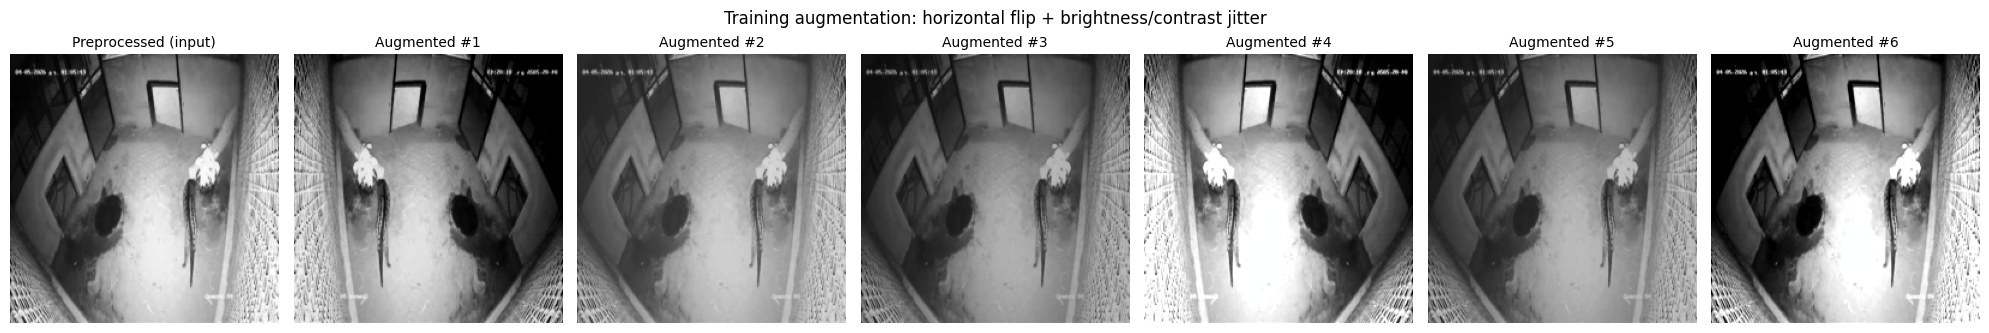

In [ ]:
# ===== Cell 5: Cache preprocessed images, augmentation and DataLoaders =====
# Input : results/c3_split.csv | Output: /content/data/*.png, c5_augmentation.png
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T
from PIL import Image

CLASSES = ['Inactive', 'Locomotion', 'Feeding_Drinking', 'Not_visible']
CLS2ID  = {c: i for i, c in enumerate(CLASSES)}
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
BATCH = 32

# ---------- Cache: run prep() once per image, save to local disk ----------
CACHE = Path('/content/data')
shutil.rmtree(CACHE, ignore_errors=True)   # always rebuild: split may have changed
CACHE.mkdir()
split = pd.read_csv(RESULTS / 'c3_split.csv')
split['cache'] = [str(CACHE / f'{i:05d}.png') for i in range(len(split))]
todo = [r for r in split.itertuples() if not Path(r.cache).exists()]
for k, r in enumerate(todo, 1):
    cv2.imwrite(r.cache, prep(cv2.imread(r.path)))
    if k % 200 == 0:
        print(f'  cached {k}/{len(todo)}')
print(f'Cached images ready: {len(split)} in {CACHE}')

# ---------- Transforms ----------
train_tf = T.Compose([
    T.RandomHorizontalFlip(p=0.5),
    T.ColorJitter(brightness=0.3, contrast=0.3),
    T.ToTensor(), T.Normalize(MEAN, STD)])
val_tf = T.Compose([T.ToTensor(), T.Normalize(MEAN, STD)])

class CivetDataset(Dataset):
    def __init__(self, df, tf):
        self.paths  = df['cache'].tolist()
        self.labels = df['cls'].map(CLS2ID).tolist()
        self.tf = tf
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        return self.tf(Image.open(self.paths[i]).convert('RGB')), self.labels[i]

train_df = split[split['split'] == 'train'].reset_index(drop=True)
val_df   = split[split['split'] == 'val'].reset_index(drop=True)
train_dl = DataLoader(CivetDataset(train_df, train_tf), batch_size=BATCH, shuffle=True,
                      num_workers=2, pin_memory=True)
val_dl   = DataLoader(CivetDataset(val_df, val_tf), batch_size=BATCH, shuffle=False,
                      num_workers=2, pin_memory=True)

x, y = next(iter(train_dl))
print(f'Train: {len(train_df)} images, {len(train_dl)} batches | Val: {len(val_df)} images, {len(val_dl)} batches')
print('Batch shape:', tuple(x.shape), '| labels in batch:', torch.bincount(y, minlength=4).tolist())

# ---------- Figure: one image x 6 random augmentations ----------
def denorm(t):
    return (t.permute(1, 2, 0).numpy() * STD + MEAN).clip(0, 1)

r = train_df[train_df['cls'] == 'Locomotion'].sample(1, random_state=SEED).iloc[0]
img = Image.open(r['cache']).convert('RGB')
fig, ax = plt.subplots(1, 7, figsize=(20, 3.4))
ax[0].imshow(img); ax[0].set_title('Preprocessed (input)', fontsize=10)
for k in range(1, 7):
    ax[k].imshow(denorm(train_tf(img))); ax[k].set_title(f'Augmented #{k}', fontsize=10)
for a in ax: a.axis('off')
plt.suptitle('Training augmentation: horizontal flip + brightness/contrast jitter')
plt.tight_layout(); plt.savefig(RESULTS / 'c5_augmentation.png', dpi=120); plt.show()

## Step 6: Model Training
ResNet18 pretrained on ImageNet, new final layer with 4 outputs.
CrossEntropy with class weights (imbalanced data), Adam lr 1e-4, batch 32, 10 epochs.
The epoch with the best validation macro-F1 is saved.

Device: cuda 
Class weights: {'Inactive': np.float32(0.9), 'Locomotion': np.float32(0.73), 'Feeding_Drinking': np.float32(1.04), 'Not_visible': np.float32(1.74)}
Epoch  1/10 | train loss 0.735 acc 0.710 F1 0.703 | val loss 0.734 acc 0.744 F1 0.741 | 6s  <- saved (best)
Epoch  2/10 | train loss 0.310 acc 0.882 F1 0.884 | val loss 0.619 acc 0.785 F1 0.779 | 6s  <- saved (best)
Epoch  3/10 | train loss 0.182 acc 0.933 F1 0.939 | val loss 0.451 acc 0.836 F1 0.840 | 6s  <- saved (best)
Epoch  4/10 | train loss 0.130 acc 0.944 F1 0.950 | val loss 0.508 acc 0.812 F1 0.818 | 6s
Epoch  5/10 | train loss 0.082 acc 0.974 F1 0.977 | val loss 0.522 acc 0.823 F1 0.821 | 7s
Epoch  6/10 | train loss 0.074 acc 0.974 F1 0.977 | val loss 0.468 acc 0.853 F1 0.864 | 7s  <- saved (best)
Epoch  7/10 | train loss 0.055 acc 0.979 F1 0.982 | val loss 0.360 acc 0.874 F1 0.881 | 6s  <- saved (best)
Epoch  8/10 | train loss 0.056 acc 0.982 F1 0.984 | val loss 0.646 acc 0.829 F1 0.839 | 7s
Epoch  9/10 | train loss 

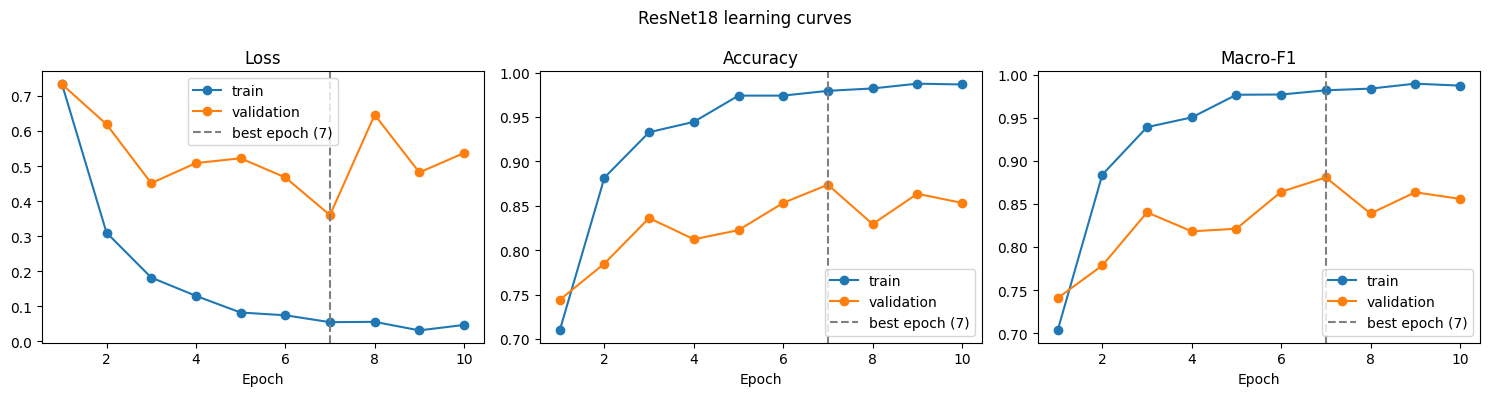

In [ ]:
# ===== Cell 6: Train ResNet18 =====
# Needs: Cell 5 (DataLoaders) | Output: models/resnet18.pt, c6_history.csv, c6_curves.png
import time
import torch.nn as nn
from torchvision import models
from sklearn.metrics import f1_score

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Device:', device, '' if device == 'cuda' else '<- WARNING: switch runtime to GPU')

EPOCHS, LR = 10, 1e-4
torch.manual_seed(SEED)

# ---------- Model ----------
model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
model.fc = nn.Linear(model.fc.in_features, len(CLASSES))
model = model.to(device)

# ---------- Class weights: rarer class -> larger weight ----------
counts  = train_df['cls'].value_counts().reindex(CLASSES).values
weights = torch.tensor(counts.sum() / (len(CLASSES) * counts), dtype=torch.float32)
print('Class weights:', dict(zip(CLASSES, weights.numpy().round(2))))
criterion = nn.CrossEntropyLoss(weight=weights.to(device))
optimizer = torch.optim.Adam(model.parameters(), lr=LR)

def run_epoch(dl, train):
    model.train(train)
    total, preds, labels = 0.0, [], []
    with torch.set_grad_enabled(train):
        for x, y in dl:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = criterion(out, y)
            if train:
                optimizer.zero_grad(); loss.backward(); optimizer.step()
            total += loss.item() * len(y)
            preds += out.argmax(1).tolist(); labels += y.tolist()
    preds, labels = np.array(preds), np.array(labels)
    return total / len(labels), (preds == labels).mean(), f1_score(labels, preds, average='macro')

# ---------- Training loop ----------
history, best_f1 = [], -1
for ep in range(1, EPOCHS + 1):
    t0 = time.time()
    tr_loss, tr_acc, tr_f1 = run_epoch(train_dl, train=True)
    va_loss, va_acc, va_f1 = run_epoch(val_dl, train=False)
    history.append(dict(epoch=ep, train_loss=tr_loss, val_loss=va_loss, train_acc=tr_acc,
                        val_acc=va_acc, train_f1=tr_f1, val_f1=va_f1))
    mark = ''
    if va_f1 > best_f1:
        best_f1, best_ep = va_f1, ep
        torch.save({'state_dict': model.state_dict(), 'classes': CLASSES, 'img_size': IMG_SIZE,
                    'mean': MEAN, 'std': STD, 'epoch': ep, 'val_f1': va_f1,
                    'unknown_threshold': None},          # set in Step 7
                   MODELS / 'resnet18.pt')
        mark = '  <- saved (best)'
    print(f'Epoch {ep:2}/{EPOCHS} | train loss {tr_loss:.3f} acc {tr_acc:.3f} F1 {tr_f1:.3f} | '
          f'val loss {va_loss:.3f} acc {va_acc:.3f} F1 {va_f1:.3f} | {time.time() - t0:.0f}s{mark}')

hist = pd.DataFrame(history)
hist.to_csv(RESULTS / 'c6_history.csv', index=False)
print(f'\nBest epoch: {best_ep} | val macro-F1 = {best_f1:.3f} | saved to {MODELS / "resnet18.pt"}')

# ---------- Figure: learning curves ----------
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, (name, key) in zip(ax, [('Loss', 'loss'), ('Accuracy', 'acc'), ('Macro-F1', 'f1')]):
    a.plot(hist['epoch'], hist[f'train_{key}'], 'o-', label='train')
    a.plot(hist['epoch'], hist[f'val_{key}'], 'o-', label='validation')
    a.axvline(best_ep, color='gray', ls='--', label=f'best epoch ({best_ep})')
    a.set_title(name); a.set_xlabel('Epoch'); a.legend()
plt.suptitle('ResNet18 learning curves')
plt.tight_layout(); plt.savefig(RESULTS / 'c6_curves.png', dpi=120); plt.show()

## Step 7: Validation Results
Classification report, confusion matrix, Active/Inactive accuracy (Not_visible reported separately),
misclassified examples, and the Unknown threshold (5th percentile of confidence on correct predictions).

Loaded model from epoch 7 (val macro-F1 0.881)
                  precision    recall  f1-score   support

        Inactive      0.934     0.695     0.797        82
      Locomotion      0.800     0.929     0.860        99
Feeding_Drinking      0.968     0.924     0.946        66
     Not_visible      0.852     1.000     0.920        46

        accuracy                          0.874       293
       macro avg      0.889     0.887     0.881       293
    weighted avg      0.884     0.874     0.871       293

Active/Inactive accuracy (visible images, n=247): 0.866
Not_visible recall (n=46): 1.000

Unknown threshold (5th pct of correct confidences): 0.749
Below threshold: 33 images | of these wrong: 20 | wrong predictions caught: 20/37


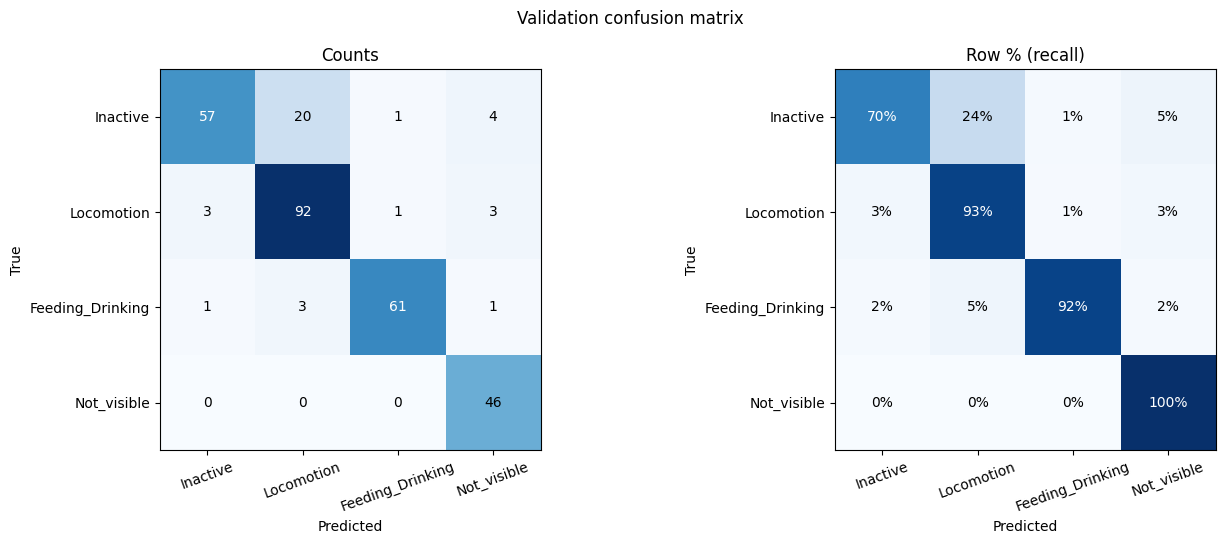

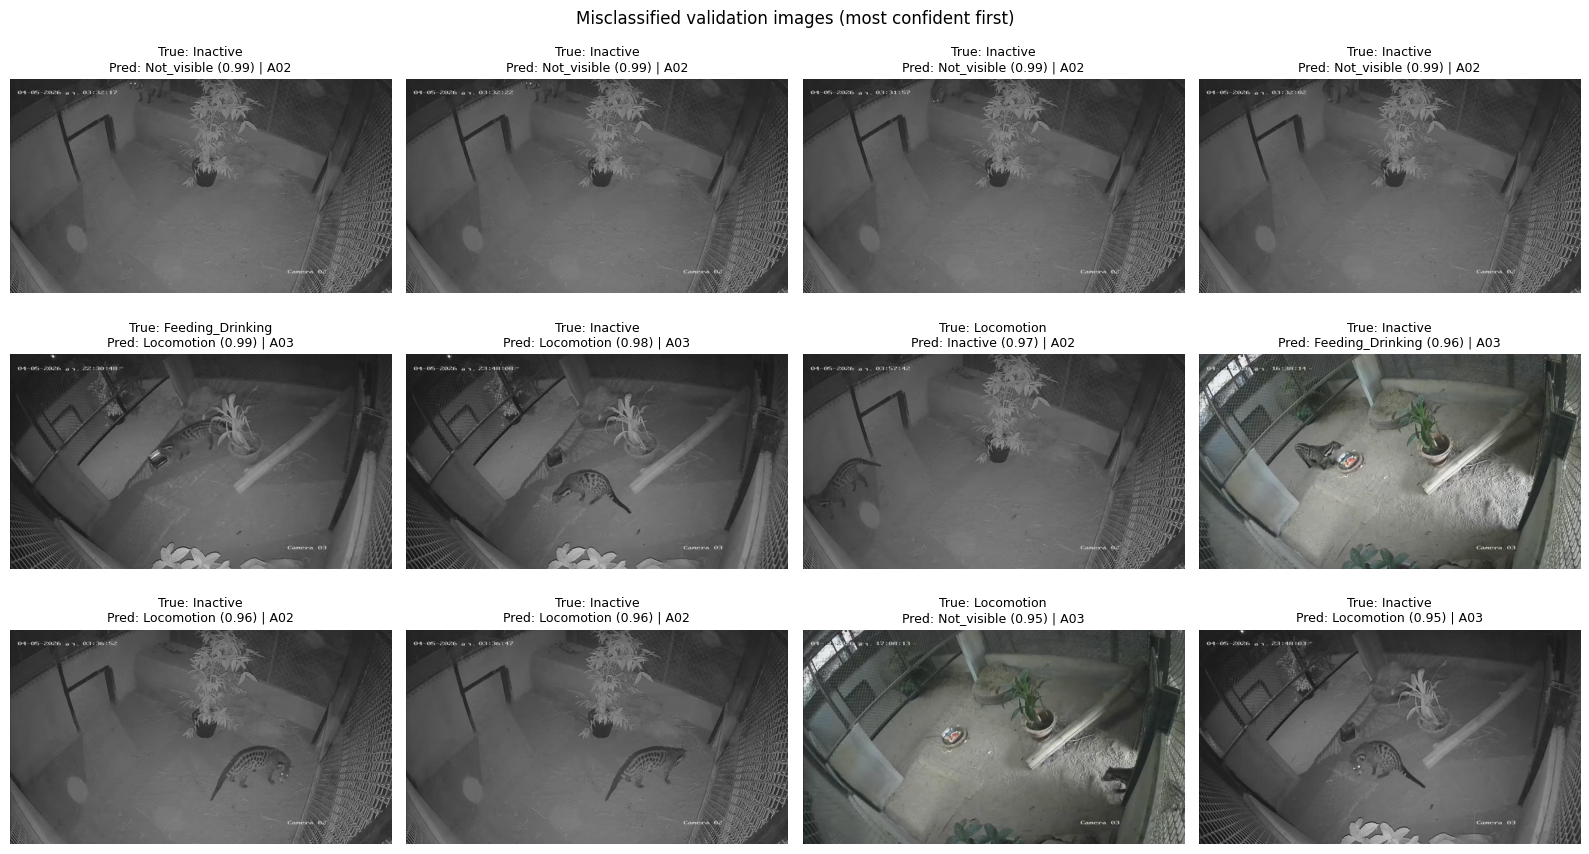

In [ ]:
# ===== Cell 7: Validation results =====
# Needs: Cell 5 (val_df, val_dl) | Output: c7_report.txt, c7_confusion.png, c7_wrong.png
#        and unknown_threshold saved into models/resnet18.pt
import torch.nn as nn
import torch.nn.functional as F
from torchvision import models
from sklearn.metrics import classification_report, confusion_matrix

device = 'cuda' if torch.cuda.is_available() else 'cpu'

# ---------- Load best model ----------
ckpt = torch.load(MODELS / 'resnet18.pt', map_location=device, weights_only=False)
model = models.resnet18()
model.fc = nn.Linear(model.fc.in_features, len(ckpt['classes']))
model.load_state_dict(ckpt['state_dict']); model.to(device).eval()
print(f"Loaded model from epoch {ckpt['epoch']} (val macro-F1 {ckpt['val_f1']:.3f})")

# ---------- Predict validation set ----------
probs = []
with torch.no_grad():
    for x, _ in val_dl:
        probs.append(F.softmax(model(x.to(device)), dim=1).cpu().numpy())
probs  = np.concatenate(probs)
pred   = probs.argmax(1)
conf   = probs.max(1)
labels = val_df['cls'].map(CLS2ID).values

# ---------- Report ----------
report = classification_report(labels, pred, target_names=CLASSES, digits=3)
print(report)

# Active / Inactive accuracy (only images where the civet is visible)
to_group = np.array([GROUP[c] for c in CLASSES])
vis = labels != CLS2ID['Not_visible']
ai_acc = (to_group[labels[vis]] == to_group[pred[vis]]).mean()
nv_true = labels == CLS2ID['Not_visible']
nv_recall = (pred[nv_true] == labels[nv_true]).mean()
print(f'Active/Inactive accuracy (visible images, n={vis.sum()}): {ai_acc:.3f}')
print(f'Not_visible recall (n={nv_true.sum()}): {nv_recall:.3f}')

# ---------- Unknown threshold ----------
correct = pred == labels
thr = float(np.percentile(conf[correct], 5))
unk = conf < thr
print(f'\nUnknown threshold (5th pct of correct confidences): {thr:.3f}')
print(f'Below threshold: {unk.sum()} images | of these wrong: {(unk & ~correct).sum()} '
      f'| wrong predictions caught: {(unk & ~correct).sum()}/{(~correct).sum()}')
ckpt['unknown_threshold'] = thr
torch.save(ckpt, MODELS / 'resnet18.pt')

with open(RESULTS / 'c7_report.txt', 'w') as f:
    f.write(f"Model epoch {ckpt['epoch']}\n\n{report}\n"
            f'Active/Inactive accuracy: {ai_acc:.3f}\nNot_visible recall: {nv_recall:.3f}\n'
            f'Unknown threshold: {thr:.3f}\n')

# ---------- Figure 1: confusion matrix (counts and row %) ----------
cm = confusion_matrix(labels, pred, labels=range(len(CLASSES)))
cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
for a, m, title, fmt in [(ax[0], cm, 'Counts', '{:.0f}'), (ax[1], cm_pct, 'Row % (recall)', '{:.0f}%')]:
    a.imshow(m, cmap='Blues')
    for i in range(len(CLASSES)):
        for j in range(len(CLASSES)):
            a.text(j, i, fmt.format(m[i, j]), ha='center', va='center',
                   color='white' if m[i, j] > m.max() / 2 else 'black')
    a.set_xticks(range(len(CLASSES)), CLASSES, rotation=20)
    a.set_yticks(range(len(CLASSES)), CLASSES)
    a.set_xlabel('Predicted'); a.set_ylabel('True'); a.set_title(title)
plt.suptitle('Validation confusion matrix')
plt.tight_layout(); plt.savefig(RESULTS / 'c7_confusion.png', dpi=120); plt.show()

# ---------- Figure 2: misclassified examples (most confident mistakes first) ----------
wrong = np.where(~correct)[0]
wrong = wrong[np.argsort(-conf[wrong])][:12]
n_col = 4
fig, ax = plt.subplots(int(np.ceil(len(wrong) / n_col)), n_col, figsize=(16, 3 * np.ceil(len(wrong) / n_col)))
for a in np.atleast_1d(ax).ravel(): a.axis('off')
for a, i in zip(np.atleast_1d(ax).ravel(), wrong):
    r = val_df.iloc[i]
    a.imshow(cv2.cvtColor(cv2.imread(r['path']), cv2.COLOR_BGR2RGB))
    a.set_title(f"True: {CLASSES[labels[i]]}\nPred: {CLASSES[pred[i]]} ({conf[i]:.2f}) | {r['camera']}", fontsize=9)
plt.suptitle('Misclassified validation images (most confident first)')
plt.tight_layout(); plt.savefig(RESULTS / 'c7_wrong.png', dpi=120); plt.show()

## Step 8: Model Explanation (Grad-CAM)
Grad-CAM on the last ResNet18 block shows which image regions drive each prediction.
Red = high importance. Two correct and one wrong example per class.

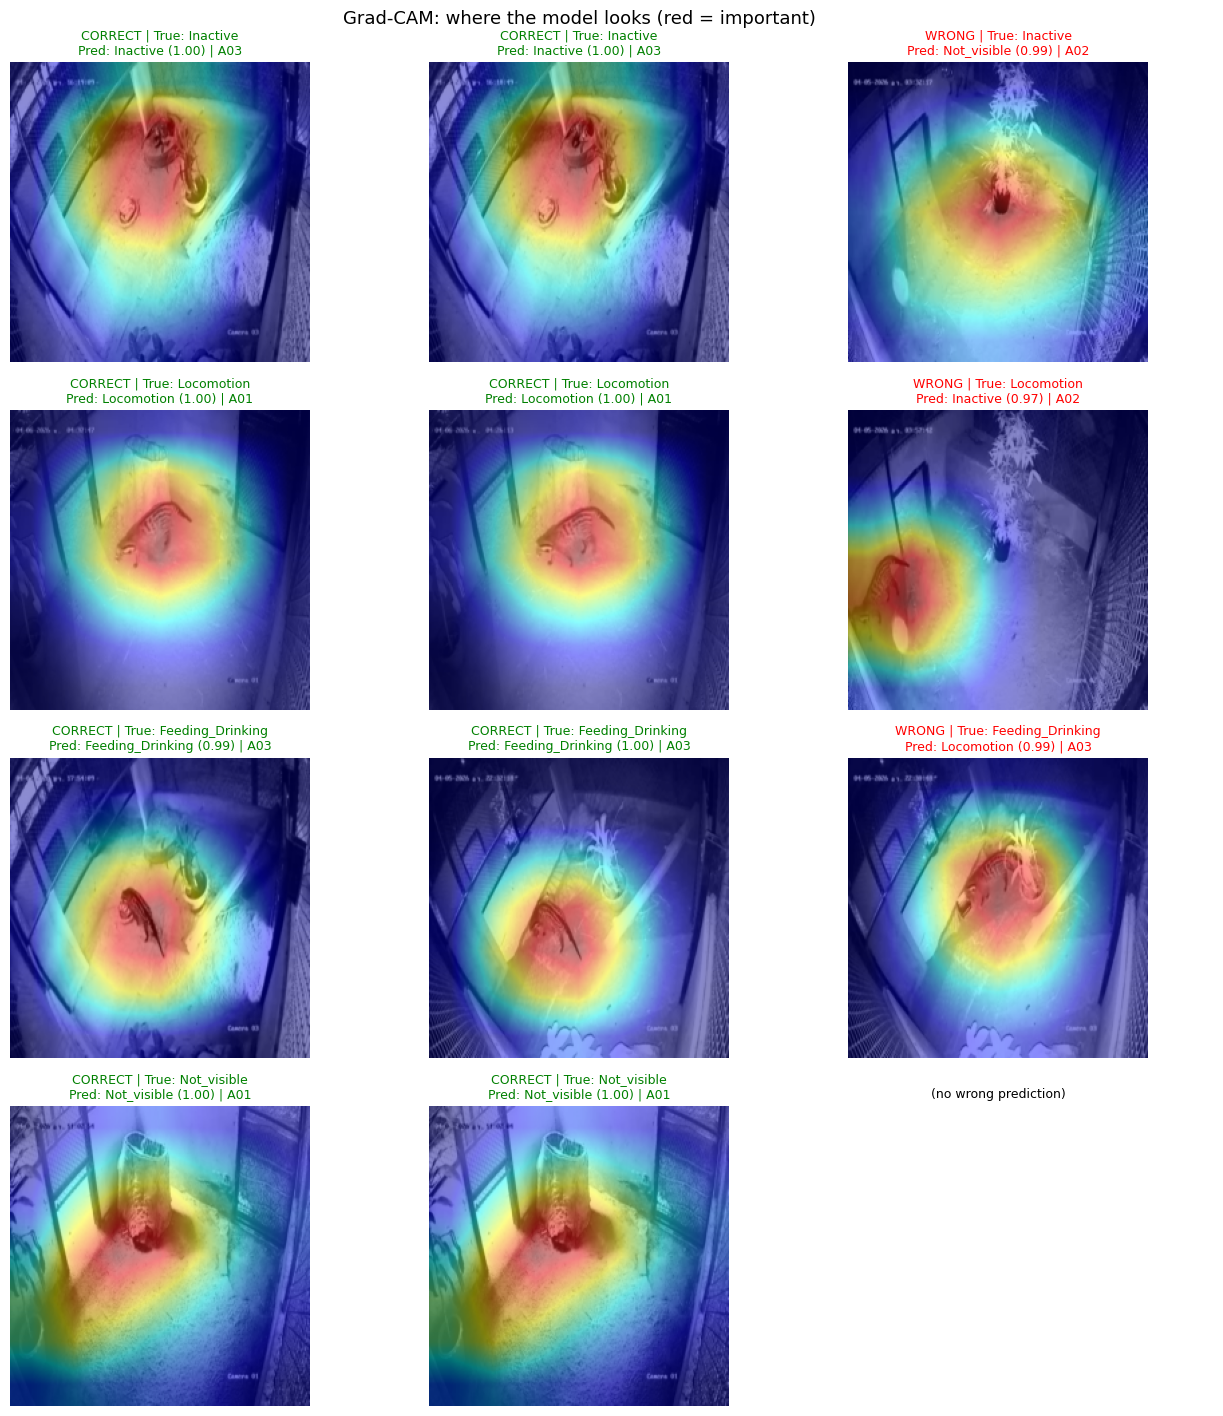

In [ ]:
# ===== Cell 8: Grad-CAM =====
# Needs: Cell 5 (val_df, val_tf), Cell 7 (model, pred, conf, labels) | Output: c8_gradcam.png

store = {}
def fwd_hook(m, i, o):
    store['act'] = o
    o.register_hook(lambda g: store.__setitem__('grad', g))
hook = model.layer4[-1].register_forward_hook(fwd_hook)

def gradcam(img_pil):
    x = val_tf(img_pil).unsqueeze(0).to(device)
    model.zero_grad()
    out = model(x)
    c = out.argmax(1).item()
    out[0, c].backward()
    w = store['grad'].mean(dim=(2, 3), keepdim=True)
    cam = F.relu((w * store['act']).sum(1)).squeeze().detach().cpu().numpy()
    cam = cv2.resize(cam, (IMG_SIZE, IMG_SIZE))
    return (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

def overlay(img_pil, cam):
    heat = cv2.cvtColor(cv2.applyColorMap(np.uint8(255 * cam), cv2.COLORMAP_JET), cv2.COLOR_BGR2RGB)
    return np.uint8(0.55 * np.array(img_pil) + 0.45 * heat)

# ---------- Pick 2 confident correct + 1 confident wrong per class ----------
rng = np.random.RandomState(SEED)
picks = []
for k, c in enumerate(CLASSES):
    ok  = np.where((labels == k) & (pred == k))[0]
    bad = np.where((labels == k) & (pred != k))[0]
    ok  = ok[np.argsort(-conf[ok])][:10]
    picks.append([*rng.choice(ok, 2, replace=False),
                  bad[np.argmax(conf[bad])] if len(bad) else None])

# ---------- Figure ----------
fig, ax = plt.subplots(len(CLASSES), 3, figsize=(13, 3.6 * len(CLASSES)))
for r, row in enumerate(picks):
    for col, i in enumerate(row):
        a = ax[r, col]; a.axis('off')
        if i is None:
            a.set_title('(no wrong prediction)', fontsize=9); continue
        img = Image.open(val_df.iloc[i]['cache']).convert('RGB')
        a.imshow(overlay(img, gradcam(img)))
        tag = 'CORRECT' if pred[i] == labels[i] else 'WRONG'
        a.set_title(f"{tag} | True: {CLASSES[labels[i]]}\nPred: {CLASSES[pred[i]]} ({conf[i]:.2f}) | "
                    f"{val_df.iloc[i]['camera']}", fontsize=9,
                    color='green' if tag == 'CORRECT' else 'red')
hook.remove()
plt.suptitle('Grad-CAM: where the model looks (red = important)', fontsize=13)
plt.tight_layout(); plt.savefig(RESULTS / 'c8_gradcam.png', dpi=120); plt.show()

## Step 9: Test on Labeled Test Hour (4 Cameras)
Predict every second of the 4 test clips with the same preprocessing, then evaluate per camera
and after combining cameras, against the hand-made ground-truth timeline.

In [ ]:
# ===== Cell 9.0: Inspect test data =====
TEST = BASE / 'test'
for p in sorted((TEST / 'hour').iterdir()):
    cap = cv2.VideoCapture(str(p))
    fps, n = cap.get(cv2.CAP_PROP_FPS), cap.get(cv2.CAP_PROP_FRAME_COUNT)
    print(f'{p.name:45} fps {fps:5.2f} | frames {n:7.0f} | {n / fps / 60:5.1f} min')
    cap.release()

for f in ['hour_labels.csv', 'hour_labels_by_camera.csv']:
    df = pd.read_csv(TEST / f)
    print(f'\n{f}: {len(df)} rows'); display(df.head(8))
    print('behavior counts:', df['behavior'].value_counts().to_dict())

A01_20260405000000.mp4                        fps 30.00 | frames  132960 |  73.9 min
A02_20260405000000-00.00.00.000-01.00.17.846.mp4 fps 30.00 | frames  108517 |  60.3 min
A03_20260405000000-00.00.00.000-01.00.09.022.mp4 fps 30.00 | frames  108270 |  60.1 min
A04_20260405000000-00.00.00.000-01.00.01.798.mp4 fps 30.00 | frames  108051 |  60.0 min

hour_labels.csv: 104 rows


,start,end,camera,behavior,note
0,00:35:39,00:35:44,A02,Locomotion,NaN
1,00:35:45,00:36:52,A03,Feeding,NaN
2,00:36:53,00:37:06,A02,Locomotion,NaN
3,00:37:07,00:37:38,A02,Other,Grooming
4,00:37:39,00:37:59,A02,Locomotion,NaN
5,00:38:00,00:38:13,A02,Other,Urination
6,00:38:14,00:38:28,A02,Resting,standing
7,00:38:29,00:38:39,A02,Locomotion,NaN


behavior counts: {'Locomotion': 64, 'Resting': 16, 'Other': 7, 'Unclear': 6, 'Feeding': 5, 'Drinking': 3, 'In_box': 3}

hour_labels_by_camera.csv: 102 rows


,start,end,camera,behavior,note
0,00:36:58,00:37:06,A01,Locomotion,NaN
1,00:37:07,00:37:39,A01,Other,Grooming
2,00:43:36,00:44:06,A01,Locomotion,NaN
3,00:53:36,00:54:01,A01,Locomotion,NaN
4,00:54:56,00:55:13,A01,Locomotion,NaN
5,00:57:19,00:57:27,A01,Locomotion,NaN
6,00:57:28,00:57:35,A01,Resting,standing
7,00:57:36,00:57:42,A01,Locomotion,NaN


behavior counts: {'Locomotion': 65, 'Resting': 16, 'Feeding': 9, 'Other': 8, 'Drinking': 3, 'Unclear': 1}


A01: copying video to local disk ...
A01: extracting 1 frame/s from 00:35:30 ...
   2071 frames: 00:35:30 -> 01:10:00
   saved 2071 seconds -> c9_pred_A01.csv
A02: copying video to local disk ...
A02: extracting 1 frame/s from 00:35:30 ...
   1488 frames: 00:35:30 -> 01:00:17
   saved 1488 seconds -> c9_pred_A02.csv
A03: copying video to local disk ...
A03: extracting 1 frame/s from 00:35:30 ...
   1479 frames: 00:35:30 -> 01:00:08
   saved 1479 seconds -> c9_pred_A03.csv
A04: copying video to local disk ...
A04: extracting 1 frame/s from 00:35:30 ...
   1472 frames: 00:35:30 -> 01:00:01
   saved 1472 seconds -> c9_pred_A04.csv

Saved 6510 rows -> /content/drive/MyDrive/civet2/results/c9_pred_raw.csv


pred,Feeding_Drinking,Inactive,Locomotion,Not_visible
camera,,,,
A01,0,76,171,1824
A02,0,235,150,1103
A03,205,0,1274,0
A04,24,3,284,1161


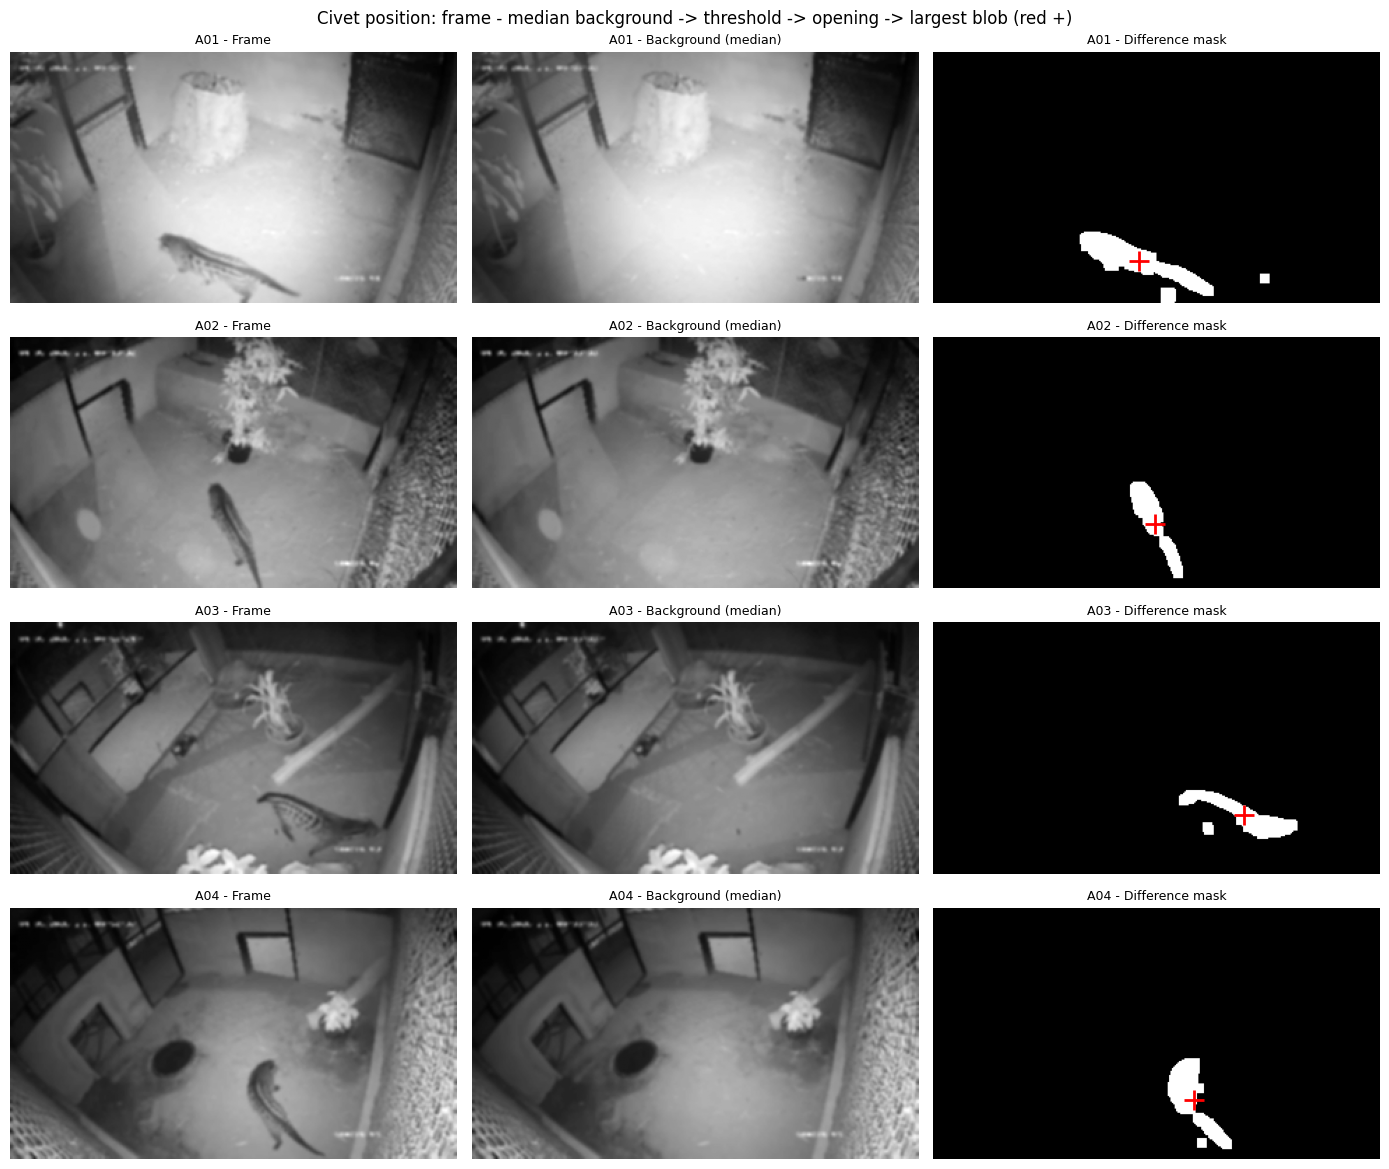

In [ ]:
# ===== Cell 9.1: Predict every second of the 4 test clips + civet position =====
# Output: results/c9_pred_<camera>.csv, c9_pred_raw.csv, c9_motion_example.png
# Frames are extracted with ffmpeg (1 frame per second): it skips damaged parts of the
# CCTV files, where OpenCV stops reading.
import subprocess
import torch.nn as nn
import torch.nn.functional as F
from torchvision import models, transforms as T
from PIL import Image

device = 'cuda' if torch.cuda.is_available() else 'cpu'
ckpt = torch.load(MODELS / 'resnet18.pt', map_location=device, weights_only=False)
CLASSES = ckpt['classes']
model = models.resnet18()
model.fc = nn.Linear(model.fc.in_features, len(CLASSES))
model.load_state_dict(ckpt['state_dict']); model.to(device).eval()
norm = T.Compose([T.ToTensor(), T.Normalize(ckpt['mean'], ckpt['std'])])

TEST  = BASE / 'test'
POS_W = 320                      # frame width used for civet position
def hms(s):
    h, m, x = map(int, s.split(':')); return h * 3600 + m * 60 + x
def fmt(sec):
    return f'{sec // 3600:02d}:{sec % 3600 // 60:02d}:{sec % 60:02d}'
T_START, T_END = hms('00:35:30'), hms('01:10:00')   # labeled window + small margin

def clip_start(p):
    """Real start time (s from midnight) = start in name + cut offset (if any)."""
    d = re.search(r'_(\d{14})', p.stem).group(1)
    sec = int(d[8:10]) * 3600 + int(d[10:12]) * 60 + int(d[12:14])
    cut = re.search(r'-(\d\d)\.(\d\d)\.(\d\d)\.\d+-', p.stem)
    if cut:
        h, m, s = map(int, cut.groups()); sec += h * 3600 + m * 60 + s
    return sec

def extract_frames(video, start, dur, out_dir):
    """ffmpeg: one JPEG per second, starting at `start` seconds into the video."""
    shutil.rmtree(out_dir, ignore_errors=True); out_dir.mkdir(parents=True)
    subprocess.run(['ffmpeg', '-v', 'error', '-ss', str(start), '-i', str(video), '-t', str(dur),
                    '-vf', 'fps=1', '-q:v', '2', str(out_dir / '%05d.jpg')])
    return sorted(out_dir.glob('*.jpg'))

# ---------- Civet position by background subtraction ----------
def small_gray(f):
    g = cv2.cvtColor(f, cv2.COLOR_BGR2GRAY)
    g = cv2.resize(g, (POS_W, int(g.shape[0] * POS_W / g.shape[1])))
    return cv2.GaussianBlur(g, (5, 5), 0)

def civet_pos(g, bg):
    d = cv2.absdiff(g, bg)
    d[:int(0.08 * d.shape[0])] = 0                                        # ignore on-screen clock
    _, m = cv2.threshold(d, 30, 255, cv2.THRESH_BINARY)
    m = cv2.morphologyEx(m, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))   # remove noise
    m = cv2.dilate(m, np.ones((5, 5), np.uint8))                          # join body parts
    n, _, stats, cent = cv2.connectedComponentsWithStats(m)
    if n < 2:
        return np.nan, np.nan, 0, m
    k = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
    return cent[k][0], cent[k][1], int(stats[k, cv2.CC_STAT_AREA]), m

def predict(batch):
    with torch.no_grad():
        return F.softmax(model(torch.stack(batch).to(device)), 1).cpu().numpy()

# ---------- Predict (one CSV per camera; complete cameras are skipped) ----------
examples = {}
for p in sorted((TEST / 'hour').glob('*.mp4')):
    cam, t0 = p.name[:3], clip_start(p)
    out_csv = RESULTS / f'c9_pred_{cam}.csv'
    if out_csv.exists() and len(pd.read_csv(out_csv)) > 1000:
        print(f'{cam}: already done, skipped'); continue

    local = Path('/content/video') / p.name
    local.parent.mkdir(exist_ok=True)
    if not local.exists():
        print(f'{cam}: copying video to local disk ...', flush=True)
        shutil.copy(p, local)
    s_from = max(T_START - t0, 0)
    print(f'{cam}: extracting 1 frame/s from {fmt(t0 + s_from)} ...', flush=True)
    jpgs = extract_frames(local, s_from, T_END - t0 - s_from + 1, Path('/content/frames') / cam)
    local.unlink()                       # free local disk
    if not jpgs:
        print(f'{cam}: no frames extracted, skipped'); continue
    print(f'   {len(jpgs)} frames: {fmt(t0 + s_from)} -> {fmt(t0 + s_from + len(jpgs) - 1)}', flush=True)

    secs, grays, probs, batch = [], [], [], []
    for k, jp in enumerate(jpgs):
        f = cv2.imread(str(jp))
        secs.append(t0 + s_from + k); grays.append(small_gray(f))
        batch.append(norm(Image.fromarray(prep(f))))
        if len(batch) == 64:
            probs.append(predict(batch)); batch = []
    if batch:
        probs.append(predict(batch))

    # civet position: median background of the window, then the largest blob per second
    bg = np.median(grays[::max(1, len(grays) // 60)], axis=0).astype(np.uint8)
    probs, rows, best = np.concatenate(probs), [], 0
    for sec, g, q in zip(secs, grays, probs):
        cx, cy, area, m = civet_pos(g, bg)
        if 0 < area < 0.2 * m.size and area > best:
            best, examples[cam] = area, (g, bg, m, cx, cy)
        rows.append({'camera': cam, 'sec': sec, 'time': fmt(sec),
                     **{f'p_{c}': round(float(v), 4) for c, v in zip(CLASSES, q)},
                     'pred': CLASSES[q.argmax()], 'conf': round(float(q.max()), 4),
                     'cx': cx, 'cy': cy, 'area': area})
    pd.DataFrame(rows).to_csv(out_csv, index=False)
    shutil.rmtree(Path('/content/frames') / cam, ignore_errors=True)
    print(f'   saved {len(rows)} seconds -> {out_csv.name}', flush=True)

raw = pd.concat([pd.read_csv(f) for f in sorted(RESULTS.glob('c9_pred_A0*.csv'))])
raw.to_csv(RESULTS / 'c9_pred_raw.csv', index=False)
print(f'\nSaved {len(raw)} rows ->', RESULTS / 'c9_pred_raw.csv')
display(pd.crosstab(raw['camera'], raw['pred']))

# ---------- Figure: background subtraction example per camera ----------
if examples:
    fig, ax = plt.subplots(len(examples), 3, figsize=(14, 3 * len(examples)), squeeze=False)
    for r, (cam, (g, bg, m, cx, cy)) in enumerate(sorted(examples.items())):
        for a, im, t in zip(ax[r], [g, bg, m], ['Frame', 'Background (median)', 'Difference mask']):
            a.imshow(im, cmap='gray'); a.set_title(f'{cam} - {t}', fontsize=9); a.axis('off')
        ax[r, 2].plot(cx, cy, 'r+', ms=14, mew=2)
    plt.suptitle('Civet position: frame - median background -> threshold -> opening -> largest blob (red +)')
    plt.tight_layout(); plt.savefig(RESULTS / 'c9_motion_example.png', dpi=120); plt.show()

Evaluation window: 00:35:39 - 01:00:01
Unknown threshold 0.749 | MOVE_PX 20 | MIN_BLOB 50


accuracy        macro_f1        active_inactive       
variant                   raw   rule      raw   rule             raw   rule
level                                                                      
A01                     0.941  0.941    0.531  0.481           0.673  0.667
A02                     0.716  0.712    0.419  0.416           0.424  0.433
A03                     0.182  0.721    0.183  0.451           0.816  0.803
A04                     0.689  0.698    0.311  0.377           0.415  0.449
All cameras (pooled)    0.633  0.768    0.420  0.481           0.561  0.569
4 cameras combined      0.506  0.508    0.378  0.406           0.757  0.701

Combined room accuracy: {'raw': 0.459, 'rule': 0.616}

A03 rule predictions vs ground truth:
rule              Feeding_Drinking  Inactive  Locomotion  Not_visible  Unknown
gt                                                                            
Feeding_Drinking                99        11           0            0        9
Inactive                        20        10           8            0        0
Locomotion                      47         4         162            0       26
Not_visible                      2        30         233          778       13
Unknown                          0         0           3            0        0


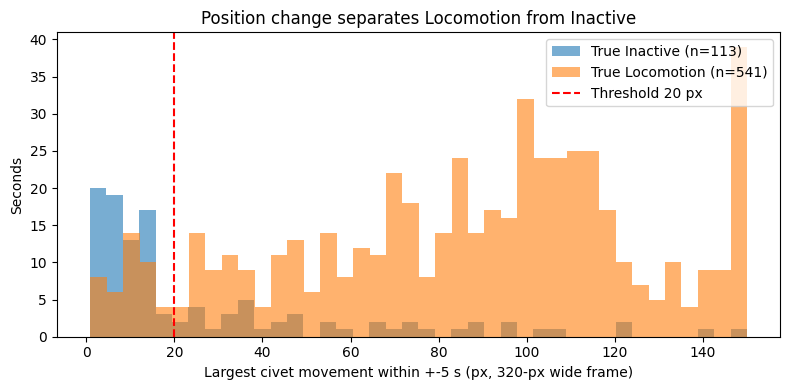

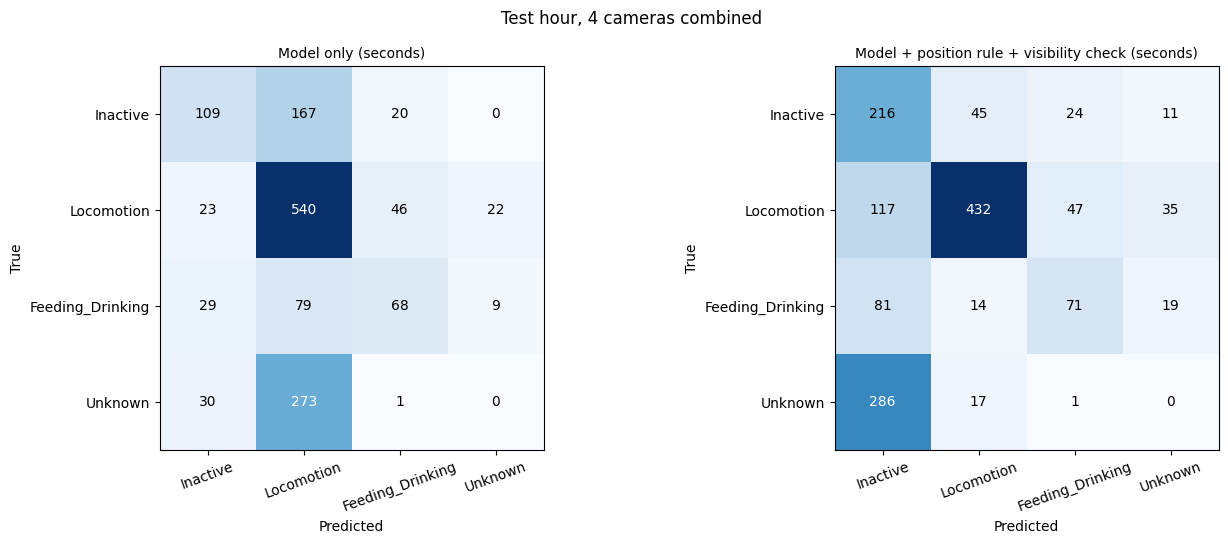

In [ ]:
# ===== Cell 9.2: Evaluation per camera and 4 cameras combined =====
# raw  = model only (+ Unknown threshold)
# rule = raw + 5-s position rule (Inactive vs Locomotion) + visibility check (moving blob)
# Input : c9_pred_raw.csv, hour_labels*.csv
# Output: c9_results.csv, c9_pred_cam.csv, c9_timeline.csv, c9_motion_hist.png, c9_confusion.png
from sklearn.metrics import f1_score, confusion_matrix

def hms(s):
    h, m, x = map(int, s.split(':'))
    return h * 3600 + m * 60 + x

def fmt(sec):
    return f'{sec // 3600:02d}:{sec % 3600 // 60:02d}:{sec % 60:02d}'

TEST = BASE / 'test'
raw = pd.read_csv(RESULTS / 'c9_pred_raw.csv')
ckpt = torch.load(MODELS / 'resnet18.pt', map_location='cpu', weights_only=False)
THR = ckpt['unknown_threshold']
MOVE_PX = 20     # moved > 20 px (320-px wide frame) within 5 s = Locomotion
SHIFT = 5        # seconds
MIN_BLOB = 50    # pixels; smaller blobs = noise
VIS_CAMS = ['A03']   # visibility check only where training has no night empty-room images
MAP = {'Resting': 'Inactive', 'Locomotion': 'Locomotion',
       'Feeding': 'Feeding_Drinking', 'Drinking': 'Feeding_Drinking',
       'Other': 'Unknown', 'In_box': 'Inactive', 'Unclear': None}

EV_START = hms('00:35:39')
last_sec = raw[raw['camera'] != 'A01'].groupby('camera')['sec'].max().min()
EV_END = min(hms('01:09:55'), last_sec)
print(f'Evaluation window: {fmt(EV_START)} - {fmt(EV_END)}')
print(f'Unknown threshold {THR:.3f} | MOVE_PX {MOVE_PX} | MIN_BLOB {MIN_BLOB}')

# ---------- Post-processing per camera ----------
def apply_rules(g):
    g = g.sort_values('sec').set_index('sec')
    xy = g[['cx', 'cy']]
    fwd = np.hypot(*(xy.reindex(g.index + SHIFT).values - xy.values).T)
    bwd = np.hypot(*(xy.values - xy.reindex(g.index - SHIFT).values).T)
    g['disp'] = np.fmax(fwd, bwd)                      # largest move within +-5 s

    unsure = (g['pred'] != 'Not_visible') & (g['conf'] < THR)
    g['raw'] = g['pred'].where(~unsure, 'Unknown')

    # 5-s position rule
    use = g['raw'].isin(['Inactive', 'Locomotion']) & g['disp'].notna()
    moved = np.where(g['disp'] > MOVE_PX, 'Locomotion', 'Inactive')
    g['rule'] = np.where(use, moved, g['raw'])

    # visibility check: no moving blob within +-5 s -> camera does not see the civet
    full = range(g.index.min(), g.index.max() + 1)
    blob = (g['area'] > MIN_BLOB).astype(float).reindex(full)
    win = blob.rolling(2 * SHIFT + 1, center=True, min_periods=1).max()
    g['seen'] = win.reindex(g.index) > 0
    if g['camera'].iloc[0] in VIS_CAMS:
      g.loc[(g['rule'] != 'Not_visible') & ~g['seen'], 'rule'] = 'Not_visible'
    return g

cam = pd.concat([apply_rules(g) for _, g in raw.groupby('camera')]).reset_index()
in_window = (cam['sec'] >= EV_START) & (cam['sec'] <= EV_END)
cam = cam[in_window].reset_index(drop=True)

# ---------- Ground truth ----------
gt_cam = {}
for r in pd.read_csv(TEST / 'hour_labels_by_camera.csv').itertuples():
    for s in range(hms(r.start), hms(r.end) + 1):
        gt_cam[(r.camera, s)] = MAP[r.behavior]
cam['gt'] = [gt_cam.get((c, s), 'Not_visible')
             for c, s in zip(cam['camera'], cam['sec'])]

gt_m = {}
for r in pd.read_csv(TEST / 'hour_labels.csv').itertuples():
    for s in range(hms(r.start), hms(r.end) + 1):
        gt_m[s] = (r.camera, MAP[r.behavior])

# ---------- Metrics ----------
LABELS = ['Inactive', 'Locomotion', 'Feeding_Drinking', 'Not_visible', 'Unknown']

def group(a):
    active = np.isin(a, ['Locomotion', 'Feeding_Drinking'])
    return np.where(a == 'Inactive', 'Inactive', np.where(active, 'Active', 'Other'))

def score(y, p):
    keep = pd.notna(y)
    y = np.asarray(y, dtype=object)[keep]
    p = np.asarray(p, dtype=object)[keep]
    labs = [l for l in LABELS if l in set(y)]
    act = np.isin(y, ['Inactive', 'Locomotion', 'Feeding_Drinking'])
    f1 = f1_score(y, p, labels=labs, average='macro', zero_division=0)
    return {'seconds': len(y),
            'accuracy': round((y == p).mean(), 3),
            'macro_f1': round(f1, 3),
            'active_inactive': round((group(y[act]) == group(p[act])).mean(), 3)}

results = []
for variant in ['raw', 'rule']:
    for c in CAMERAS:
        d = cam[cam['camera'] == c]
        if len(d):
            results.append({'level': c, 'variant': variant,
                            **score(d['gt'], d[variant])})
    results.append({'level': 'All cameras (pooled)', 'variant': variant,
                    **score(cam['gt'], cam[variant])})

# ---------- Combine 4 cameras per second ----------
def combine(col):
    out = []
    for s, g in cam.groupby('sec'):
        vis = g[g[col] != 'Not_visible']
        if len(vis):
            r = vis.loc[vis['conf'].idxmax()]
            out.append((s, r['camera'], r[col]))
        else:
            out.append((s, 'A02', 'Inactive'))      # all cameras Not_visible -> in box
    return pd.DataFrame(out, columns=['sec', f'room_{col}', f'beh_{col}'])

tl = combine('raw').merge(combine('rule'), on='sec')
tl['time'] = tl['sec'].map(fmt)
tl['gt'] = [gt_m.get(s, (None, None))[1] for s in tl['sec']]
tl['gt_room'] = [gt_m.get(s, (None, None))[0] for s in tl['sec']]
ok = tl['gt'].notna()
for variant in ['raw', 'rule']:
    sc = score(tl['gt'], tl[f'beh_{variant}'])
    room_ok = tl.loc[ok, f'room_{variant}'] == tl.loc[ok, 'gt_room']
    sc['room_accuracy'] = round(room_ok.mean(), 3)
    results.append({'level': '4 cameras combined', 'variant': variant, **sc})

res = pd.DataFrame(results)
res.to_csv(RESULTS / 'c9_results.csv', index=False)
cam.to_csv(RESULTS / 'c9_pred_cam.csv', index=False)
tl.to_csv(RESULTS / 'c9_timeline.csv', index=False)
display(res.pivot_table(index='level', columns='variant', sort=False,
                        values=['accuracy', 'macro_f1', 'active_inactive']))
comb = res[res['level'] == '4 cameras combined']
print('Combined room accuracy:', dict(zip(comb['variant'], comb['room_accuracy'])))
print('\nA03 rule predictions vs ground truth:')
a3 = cam[cam['camera'] == 'A03']
print(pd.crosstab(a3['gt'], a3['rule']))

# ---------- Figure 1: displacement for true Locomotion vs true Inactive ----------
plt.figure(figsize=(8, 4))
for lab, c in [('Inactive', 'tab:blue'), ('Locomotion', 'tab:orange')]:
    sel = (cam['gt'] == lab) & cam['disp'].notna()
    v = cam.loc[sel, 'disp'].clip(upper=150)
    plt.hist(v, bins=40, alpha=0.6, color=c, label=f'True {lab} (n={len(v)})')
plt.axvline(MOVE_PX, color='red', ls='--', label=f'Threshold {MOVE_PX} px')
plt.xlabel('Largest civet movement within +-5 s (px, 320-px wide frame)')
plt.ylabel('Seconds')
plt.title('Position change separates Locomotion from Inactive')
plt.legend()
plt.tight_layout()
plt.savefig(RESULTS / 'c9_motion_hist.png', dpi=120)
plt.show()

# ---------- Figure 2: combined confusion matrix, raw vs rule ----------
seen_labels = set(tl.loc[ok, 'gt']) | set(tl['beh_raw']) | set(tl['beh_rule'])
labs = [l for l in LABELS if l in seen_labels]
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
for a, variant in zip(ax, ['raw', 'rule']):
    m = confusion_matrix(tl.loc[ok, 'gt'], tl.loc[ok, f'beh_{variant}'], labels=labs)
    a.imshow(m, cmap='Blues')
    for i in range(len(labs)):
        for j in range(len(labs)):
            color = 'white' if m[i, j] > m.max() / 2 else 'black'
            a.text(j, i, m[i, j], ha='center', va='center', color=color)
    a.set_xticks(range(len(labs)), labs, rotation=20)
    a.set_yticks(range(len(labs)), labs)
    a.set_xlabel('Predicted')
    a.set_ylabel('True')
    name = 'Model only' if variant == 'raw' else 'Model + position rule + visibility check'
    a.set_title(f'{name} (seconds)', fontsize=10)
plt.suptitle('Test hour, 4 cameras combined')
plt.tight_layout()
plt.savefig(RESULTS / 'c9_confusion.png', dpi=120)
plt.show()

## Step 10: Output — Timeline and Observation Sheet
5-s majority smoothing, Feeding_Drinking split by room (A03 → Feeding, A04 → Drinking),
per-minute observation table, Feeding/Drinking event counts (merge gaps < 60 s, drop events < 5 s),
system vs ground-truth timeline, and an Excel observation sheet.

After smoothing: behavior accuracy 0.534
Active/Inactive (a) trained behaviors only, n=1112: 0.728
Active/Inactive (b) ground-truth Unknown = Active, n=1416: 0.580

Event counts (system vs ground truth):


source,Ground truth,System
behavior,,
Drinking,2,1
Feeding,4,5


,date,time,room,behavior,status,active_s,inactive_s,feeding_events,drinking_events,gt_behavior
0,2026-04-05,00:35,A03 food tray,Feeding,Active,21,0,1,0,Feeding
1,2026-04-05,00:36,A03 food tray,Feeding,Active,46,14,0,0,Feeding
2,2026-04-05,00:37,A01 empty room,Inactive,Inactive,1,59,0,0,Unknown
3,2026-04-05,00:38,A02 sleeping box,Inactive,Inactive,0,60,0,0,Unknown
4,2026-04-05,00:39,A02 sleeping box,Inactive,Inactive,0,60,0,0,Unknown
5,2026-04-05,00:40,A03 food tray,Locomotion,Active,49,3,1,1,Locomotion
6,2026-04-05,00:41,A04 water tray,Locomotion,Active,37,13,1,0,Inactive
7,2026-04-05,00:42,A02 sleeping box,Inactive,Inactive,25,27,0,0,Feeding
8,2026-04-05,00:43,A03 food tray,Locomotion,Active,51,9,0,0,Locomotion
9,2026-04-05,00:44,A02 sleeping box,Inactive,Inactive,6,54,0,0,Inactive


,0
date,2026-04-05
window,00:35:39 - 01:00:01
minutes,24.4
active_%,47.9
inactive_%,49.2
gt_active_%,55.8
gt_active_incl_unknown_%,76.6
gt_inactive_%,20.2
feeding_events,5
gt_feeding_events,4


,system_s,ground_truth_s,system_%,ground_truth_%
Inactive,720,296,49.2,20.2
Locomotion,561,631,38.3,43.1
Feeding,135,119,9.2,8.1
Drinking,5,66,0.3,4.5
Unknown,42,304,2.9,20.8
Unclear,0,47,0.0,3.2


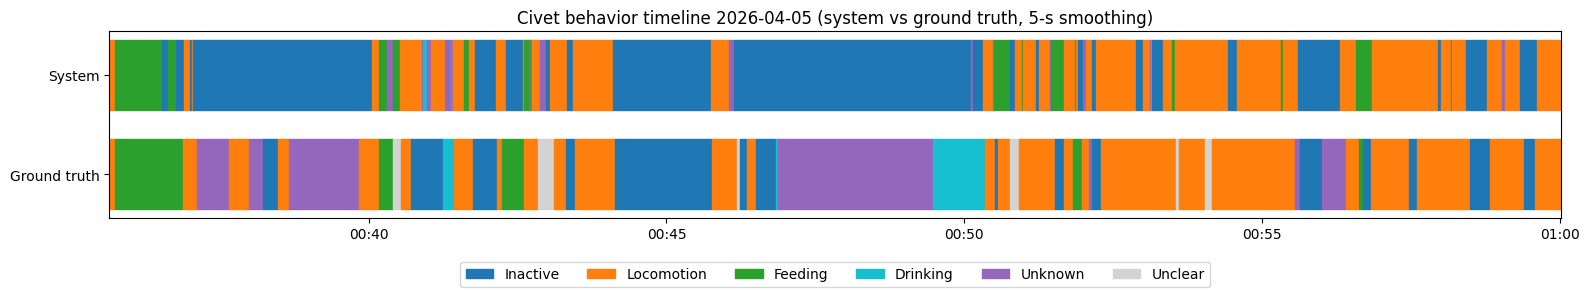

Saved: /content/drive/MyDrive/civet2/results/observation_sheet.xlsx


In [ ]:
# ===== Cell 10: Timeline, event counts and observation sheet =====
# Input : c9_timeline.csv | Output: c10_timeline.png, observation_sheet.xlsx
DATE = '2026-04-05'
SMOOTH_S = 5        # majority vote window (s)
MERGE_GAP_S = 60    # merge Feeding/Drinking events closer than this (s)
MIN_EVENT_S = 5     # drop events shorter than this (s)
ROOM = {'A01': 'A01 empty room', 'A02': 'A02 sleeping box',
        'A03': 'A03 food tray', 'A04': 'A04 water tray'}

def fmt(sec):
    return f'{sec // 3600:02d}:{sec % 3600 // 60:02d}:{sec % 60:02d}'

tl = pd.read_csv(RESULTS / 'c9_timeline.csv').sort_values('sec').reset_index(drop=True)

# ---------- 5-s majority smoothing ----------
def smooth(values, k=SMOOTH_S):
    v, h = list(values), k // 2
    return [Counter(v[max(0, i - h): i + h + 1]).most_common(1)[0][0]
            for i in range(len(v))]

def split_fd(beh, room):
    """Feeding_Drinking -> Feeding (A03) or Drinking (A04)."""
    if beh != 'Feeding_Drinking':
        return beh
    return 'Drinking' if room == 'A04' else 'Feeding'

def status(beh):
    if beh == 'Inactive':
        return 'Inactive'
    if beh in ('Locomotion', 'Feeding', 'Drinking'):
        return 'Active'
    return beh            # Unknown / Unclear

tl['sys_room'] = smooth(tl['room_rule'])
tl['sys_beh'] = [split_fd(b, r) for b, r in zip(smooth(tl['beh_rule']), tl['sys_room'])]
tl['gt_beh'] = [split_fd(b, r) if isinstance(b, str) else 'Unclear'
                for b, r in zip(tl['gt'], tl['gt_room'])]
tl['sys_status'] = tl['sys_beh'].map(status)
tl['gt_status'] = tl['gt_beh'].map(status)

ok = tl['gt_beh'] != 'Unclear'
acc = (tl.loc[ok, 'sys_beh'] == tl.loc[ok, 'gt_beh']).mean()

# Active/Inactive (a): only seconds whose ground truth is a trained behavior
vis = ok & tl['gt_status'].isin(['Active', 'Inactive'])
ai = (tl.loc[vis, 'sys_status'] == tl.loc[vis, 'gt_status']).mean()

# Active/Inactive (b): ground-truth Unknown (Grooming, Urination, ...) counted as Active (ethogram)
tl['gt_status_eth'] = tl['gt_status'].replace({'Unknown': 'Active'})
vis_eth = ok & tl['gt_status_eth'].isin(['Active', 'Inactive'])
ai_eth = (tl.loc[vis_eth, 'sys_status'] == tl.loc[vis_eth, 'gt_status_eth']).mean()

print(f'After smoothing: behavior accuracy {acc:.3f}')
print(f'Active/Inactive (a) trained behaviors only, n={vis.sum()}: {ai:.3f}')
print(f'Active/Inactive (b) ground-truth Unknown = Active, n={vis_eth.sum()}: {ai_eth:.3f}')

# ---------- Feeding / Drinking events ----------
def events(df, col, target):
    secs = df.loc[df[col] == target, 'sec'].tolist()
    runs = []
    for s in secs:
        if runs and s - runs[-1][1] <= 1:
            runs[-1][1] = s
        else:
            runs.append([s, s])
    merged = []
    for r in runs:
        if merged and r[0] - merged[-1][1] - 1 < MERGE_GAP_S:
            merged[-1][1] = r[1]
        else:
            merged.append(r)
    return [(a, b) for a, b in merged if b - a + 1 >= MIN_EVENT_S]

ev_rows = []
for who, col in [('System', 'sys_beh'), ('Ground truth', 'gt_beh')]:
    for target in ['Feeding', 'Drinking']:
        for a, b in events(tl, col, target):
            ev_rows.append({'source': who, 'behavior': target, 'start': fmt(a),
                            'end': fmt(b), 'duration_s': b - a + 1, 'start_sec': a})
ev = pd.DataFrame(ev_rows, columns=['source', 'behavior', 'start', 'end',
                                    'duration_s', 'start_sec'])
print('\nEvent counts (system vs ground truth):')
display(pd.crosstab(ev['behavior'], ev['source']))

# ---------- Per-minute observation table ----------
tl['minute'] = tl['sec'] // 60 * 60
minute_rows = []
for m, g in tl.groupby('minute'):
    starts = ev[(ev['source'] == 'System') & (ev['start_sec'] // 60 * 60 == m)]
    minute_rows.append({
        'date': DATE, 'time': fmt(m)[:5],
        'room': ROOM[g['sys_room'].mode()[0]],
        'behavior': g['sys_beh'].mode()[0],
        'status': g['sys_status'].mode()[0],
        'active_s': int((g['sys_status'] == 'Active').sum()),
        'inactive_s': int((g['sys_status'] == 'Inactive').sum()),
        'feeding_events': int((starts['behavior'] == 'Feeding').sum()),
        'drinking_events': int((starts['behavior'] == 'Drinking').sum()),
        'gt_behavior': g['gt_beh'].mode()[0]})
minute_tab = pd.DataFrame(minute_rows)
display(minute_tab.head(10))

# ---------- Summaries ----------
n = len(tl)
def n_events(src, beh):
    return int(((ev['source'] == src) & (ev['behavior'] == beh)).sum())

hourly = pd.DataFrame([{
    'date': DATE,
    'window': f"{tl['time'].iloc[0]} - {tl['time'].iloc[-1]}",
    'minutes': round(n / 60, 1),
    'active_%': round((tl['sys_status'] == 'Active').mean() * 100, 1),
    'inactive_%': round((tl['sys_status'] == 'Inactive').mean() * 100, 1),
    'gt_active_%': round((tl['gt_status'] == 'Active').mean() * 100, 1),
    'gt_active_incl_unknown_%': round((tl['gt_status_eth'] == 'Active').mean() * 100, 1),
    'gt_inactive_%': round((tl['gt_status'] == 'Inactive').mean() * 100, 1),
    'feeding_events': n_events('System', 'Feeding'),
    'gt_feeding_events': n_events('Ground truth', 'Feeding'),
    'drinking_events': n_events('System', 'Drinking'),
    'gt_drinking_events': n_events('Ground truth', 'Drinking'),
    'behavior_accuracy': round(acc, 3),
    'active_inactive_accuracy_a': round(ai, 3),
    'active_inactive_accuracy_b_unknown_as_active': round(ai_eth, 3)}])

BEH = ['Inactive', 'Locomotion', 'Feeding', 'Drinking', 'Unknown', 'Unclear']
beh_sum = pd.DataFrame({
    'system_s': tl['sys_beh'].value_counts().reindex(BEH, fill_value=0),
    'ground_truth_s': tl['gt_beh'].value_counts().reindex(BEH, fill_value=0)})
beh_sum['system_%'] = (beh_sum['system_s'] / n * 100).round(1)
beh_sum['ground_truth_%'] = (beh_sum['ground_truth_s'] / n * 100).round(1)
display(hourly.T)
display(beh_sum)

# ---------- Figure: system vs ground-truth timeline ----------
COL = {'Inactive': 'tab:blue', 'Locomotion': 'tab:orange', 'Feeding': 'tab:green',
       'Drinking': 'tab:cyan', 'Unknown': 'tab:purple', 'Unclear': 'lightgray'}

def bars(col):
    out, start = [], 0
    v = tl[col].tolist()
    for i in range(1, len(v) + 1):
        if i == len(v) or v[i] != v[start]:
            out.append((tl['sec'].iloc[start], i - start, v[start]))
            start = i
    return out

fig, ax = plt.subplots(figsize=(16, 3.2))
rows_plot = [('Ground truth', 'gt_beh'), ('System', 'sys_beh')]
for y, (name, col) in enumerate(rows_plot):
    for x0, w, lab in bars(col):
        ax.broken_barh([(x0, w)], (y - 0.35, 0.7), color=COL.get(lab, 'black'))
ax.set_yticks([0, 1], ['Ground truth', 'System'])
t0, t1 = tl['sec'].iloc[0], tl['sec'].iloc[-1]
ticks = list(range(t0 // 300 * 300 + 300, t1, 300))
ax.set_xticks(ticks, [fmt(t)[:5] for t in ticks])
ax.set_xlim(t0, t1)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in COL.values()]
ax.legend(handles, COL.keys(), ncol=6, loc='upper center', bbox_to_anchor=(0.5, -0.2))
ax.set_title(f'Civet behavior timeline {DATE} (system vs ground truth, 5-s smoothing)')
plt.tight_layout()
plt.savefig(RESULTS / 'c10_timeline.png', dpi=120)
plt.show()

# ---------- Excel observation sheet ----------
xlsx = RESULTS / 'observation_sheet.xlsx'
with pd.ExcelWriter(xlsx) as w:
    minute_tab.to_excel(w, sheet_name='Timeline', index=False)
    hourly.to_excel(w, sheet_name='Hourly summary', index=False)
    beh_sum.to_excel(w, sheet_name='Behavior summary')
    ev.drop(columns='start_sec').to_excel(w, sheet_name='Events', index=False)
print('Saved:', xlsx)